In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

DATASET_PATH = os.path.join(PROJECT_PATH, "dataset")
NOTEBOOK_PATH = os.path.join(PROJECT_PATH, "notebooks")
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")
GRAPH_PATH = os.path.join(RESULTS_PATH, "graphs")

print("Project Path:", PROJECT_PATH)
print("Model Path:", MODEL_PATH)
print("Results Path:", RESULTS_PATH)
print("Graph Path:", GRAPH_PATH)

print("\nProject Directory Exists:", os.path.exists(PROJECT_PATH))


Project Path: /content/drive/MyDrive/Marketing-Campaign-Prediction
Model Path: /content/drive/MyDrive/Marketing-Campaign-Prediction/models
Results Path: /content/drive/MyDrive/Marketing-Campaign-Prediction/results
Graph Path: /content/drive/MyDrive/Marketing-Campaign-Prediction/results/graphs

Project Directory Exists: True


In [ ]:

import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

print("\nChecking project files:")

required_files = [
    os.path.join(MODEL_PATH, "processed_data.pkl"),
    os.path.join(MODEL_PATH, "preprocessor.pkl"),
    os.path.join(MODEL_PATH, "scaler.pkl"),
    os.path.join(MODEL_PATH, "random_forest_model.pkl"),
    os.path.join(RESULTS_PATH, "random_forest_results.json")
]

for file in required_files:
    print(os.path.basename(file), ":", os.path.exists(file))


TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
Pandas Version: 2.2.3

Checking project files:
processed_data.pkl : True
preprocessor.pkl : True
scaler.pkl : True
random_forest_model.pkl : True
random_forest_results.json : True


In [ ]:

# Load previously saved processed data

data = joblib.load(
    os.path.join(MODEL_PATH, "processed_data.pkl")
)

print("Available Keys:")
print(data.keys())

print("\n" + "="*50)
print("DATASET SHAPES")
print("="*50)

for key, value in data.items():

    if hasattr(value, "shape"):
        print(f"{key}: {value.shape}")

    elif key == "class_weights":
        print(f"{key}: {value}")

    else:
        print(f"{key}: {type(value)}")


Available Keys:
dict_keys(['X_train_ml', 'X_test_ml', 'X_train_ann', 'X_test_ann', 'y_train', 'y_test', 'class_weights'])

DATASET SHAPES
X_train_ml: (36168, 50)
X_test_ml: (9043, 50)
X_train_ann: (36168, 50)
X_test_ann: (9043, 50)
y_train: (36168,)
y_test: (9043,)
class_weights: {np.int64(0): np.float64(0.5662397845758838), np.int64(1): np.float64(4.27416686362562)}


In [ ]:

scaler = joblib.load(
    os.path.join(MODEL_PATH, "scaler.pkl")
)

print("Scaler Type:", type(scaler).__name__)

if hasattr(scaler, "mean_"):
    print("\nNumber of scaled features:", len(scaler.mean_))
    print("Scaler means:", scaler.mean_[:10])
    print("Scaler standard deviations:", scaler.scale_[:10])

print("\nScaler inspection completed.")


Scaler Type: StandardScaler

Number of scaled features: 6
Scaler means: [4.08929993e+01 1.36549342e+03 1.58179606e+01 2.76393497e+00
 4.01572384e+01 5.81729706e-01]
Scaler standard deviations: [1.06269278e+01 3.06850108e+03 8.33186470e+00 3.10411781e+00
 1.00161229e+02 2.40873222e+00]

Scaler inspection completed.


In [ ]:

# Load ANN datasets

X_train = data["X_train_ann"]
X_test = data["X_test_ann"]

y_train = data["y_train"]
y_test = data["y_test"]

class_weights = data["class_weights"]

# Convert inputs into NumPy arrays
X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train = np.asarray(y_train, dtype=np.float32)
y_test = np.asarray(y_test, dtype=np.float32)

# Verify dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Check missing and infinite values
print("\nMissing Values:", np.isnan(X_train).sum())
print("Infinite Values:", np.isinf(X_train).sum())

print("\nTarget Classes:", np.unique(y_train))
print("Class Weights:", class_weights)


Training Features: (36168, 50)
Testing Features: (9043, 50)
Training Target: (36168,)
Testing Target: (9043,)

Missing Values: 0
Infinite Values: 0

Target Classes: [0. 1.]
Class Weights: {np.int64(0): np.float64(0.5662397845758838), np.int64(1): np.float64(4.27416686362562)}


In [ ]:

# Build Artificial Neural Network

ann_model = keras.Sequential([
    layers.Input(shape=(50,), name="input_layer"),

    layers.Dense(64, activation="relu", name="hidden_layer_1"),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu", name="hidden_layer_2"),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid", name="output_layer")
])

# Compile the model
ann_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("ANN Model Created Successfully!")


ANN Model Created Successfully!


In [ ]:

ann_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,377 (21.00 KB)

 Trainable params: 5,377 (21.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Restore all previously processed datasets

import joblib
import os

processed_path = os.path.join(
    PROJECT_PATH, "models", "processed_data.pkl"
)

processed_data = joblib.load(processed_path)

X_train_ml = processed_data["X_train_ml"]
X_test_ml = processed_data["X_test_ml"]

X_train_ann = processed_data["X_train_ann"]
X_test_ann = processed_data["X_test_ann"]

y_train = processed_data["y_train"]
y_test = processed_data["y_test"]

class_weights = processed_data["class_weights"]

print("All variables restored successfully!")

print("X_train_ml:", X_train_ml.shape)
print("X_train_ann:", X_train_ann.shape)
print("y_train:", y_train.shape)
print("class_weights:", class_weights)


All variables restored successfully!
X_train_ml: (36168, 50)
X_train_ann: (36168, 50)
y_train: (36168,)
class_weights: {np.int64(0): np.float64(0.5662397845758838), np.int64(1): np.float64(4.27416686362562)}


In [ ]:

from sklearn.model_selection import train_test_split

# Create ANN training and validation datasets

X_train_ann, X_val_ann, y_train_ann, y_val_ann = train_test_split(
    X_train_ann,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training Data:", X_train_ann.shape)
print("Validation Data:", X_val_ann.shape)

print("\nTraining Target:", y_train_ann.shape)
print("Validation Target:", y_val_ann.shape)

print("\nTraining Class Distribution:")
print(y_train_ann.value_counts() if hasattr(y_train_ann, "value_counts")
      else __import__("numpy").unique(y_train_ann, return_counts=True))

print("\nValidation Class Distribution:")
print(y_val_ann.value_counts() if hasattr(y_val_ann, "value_counts")
      else __import__("numpy").unique(y_val_ann, return_counts=True))


Training Data: (28934, 50)
Validation Data: (7234, 50)

Training Target: (28934,)
Validation Target: (7234,)

Training Class Distribution:
y
0    25549
1     3385
Name: count, dtype: int64

Validation Class Distribution:
y
0    6388
1     846
Name: count, dtype: int64


In [ ]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print("EarlyStopping and ModelCheckpoint imported successfully!")

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print("EarlyStopping and ModelCheckpoint imported successfully!")


EarlyStopping and ModelCheckpoint imported successfully!
EarlyStopping and ModelCheckpoint imported successfully!


In [ ]:

import os

MODEL_PATH = os.path.join(PROJECT_PATH, "models")

# Verify the folder exists
os.makedirs(MODEL_PATH, exist_ok=True)

print("MODEL_PATH:", MODEL_PATH)
print("Models folder exists:", os.path.exists(MODEL_PATH))


MODEL_PATH: /content/drive/MyDrive/Marketing-Campaign-Prediction/models
Models folder exists: True


In [ ]:

# Convert class weights into standard Python values

ann_class_weights = {
    int(key): float(value)
    for key, value in class_weights.items()
}

# Create callbacks

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath=os.path.join(MODEL_PATH, "ann_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("Class Weights:", ann_class_weights)
print("\nEarlyStopping configured.")
print("ModelCheckpoint configured.")


Class Weights: {0: 0.5662397845758838, 1: 4.27416686362562}

EarlyStopping configured.
ModelCheckpoint configured.


In [ ]:

# Train ANN Model

start_time = time.time()

history = ann_model.fit(
    X_train_ann,
    y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=100,
    batch_size=32,
    class_weight=ann_class_weights,
    callbacks=[
        early_stopping,
        model_checkpoint
    ],
    verbose=1
)

end_time = time.time()

training_time = end_time - start_time

print("\nANN Training Completed!")
print(f"Training Time: {training_time:.2f} seconds")
print(f"Epochs Completed: {len(history.history['loss'])}")
print(f"Best Validation Loss: {min(history.history['val_loss']):.4f}")
print(f"Best Validation Accuracy: {max(history.history['val_accuracy']):.4f}")


Epoch 1/100
882/905 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6462 - loss: 0.6403
Epoch 1: val_loss improved from None to 0.53603, saving model to /content/drive/MyDrive/Marketing-Campaign-Prediction/models/ann_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Marketing-Campaign-Prediction/models/ann_best.keras
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6990 - loss: 0.6083 - val_accuracy: 0.7939 - val_loss: 0.5360
Epoch 2/100
905/905 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7627 - loss: 0.5703
Epoch 2: val_loss did not improve from 0.53603
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7614 - loss: 0.5720 - val_accuracy: 0.7777 - val_loss: 0.5655
Epoch 3/100
886/905 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7684 - loss: 0.5686
Epoch 3: val_loss did not improve from 0.53603
905/905 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7703 - loss: 0.5658 - val_accuracy: 0.7889 - val_loss: 0.5410
Epoch 4/100
892/905 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Predict probabilities on unseen test data
y_pred_prob = ann_model.predict(X_test, verbose=0).ravel()

# Convert probabilities into binary predictions
y_pred = (y_pred_prob >= 0.5).astype(int)

# Calculate evaluation metrics
ann_accuracy = accuracy_score(y_test, y_pred)
ann_precision = precision_score(y_test, y_pred, zero_division=0)
ann_recall = recall_score(y_test, y_pred, zero_division=0)
ann_f1 = f1_score(y_test, y_pred, zero_division=0)
ann_roc_auc = roc_auc_score(y_test, y_pred_prob)

# Confusion matrix
ann_cm = confusion_matrix(y_test, y_pred)

# Display results
print("ANN TEST RESULTS")
print("=" * 40)

print(f"Accuracy:  {ann_accuracy:.4f}")
print(f"Precision: {ann_precision:.4f}")
print(f"Recall:    {ann_recall:.4f}")
print(f"F1-Score:  {ann_f1:.4f}")
print(f"ROC-AUC:   {ann_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(ann_cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Subscription", "Yes Subscription"],
    zero_division=0
))


ANN TEST RESULTS
Accuracy:  0.8256
Precision: 0.3548
Recall:    0.5992
F1-Score:  0.4457
ROC-AUC:   0.7914

Confusion Matrix:
[[6832 1153]
 [ 424  634]]

Classification Report:
                  precision    recall  f1-score   support

 No Subscription       0.94      0.86      0.90      7985
Yes Subscription       0.35      0.60      0.45      1058

        accuracy                           0.83      9043
       macro avg       0.65      0.73      0.67      9043
    weighted avg       0.87      0.83      0.84      9043



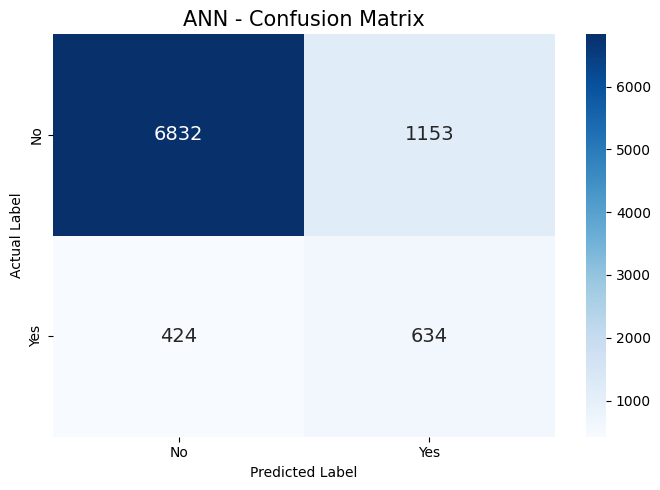

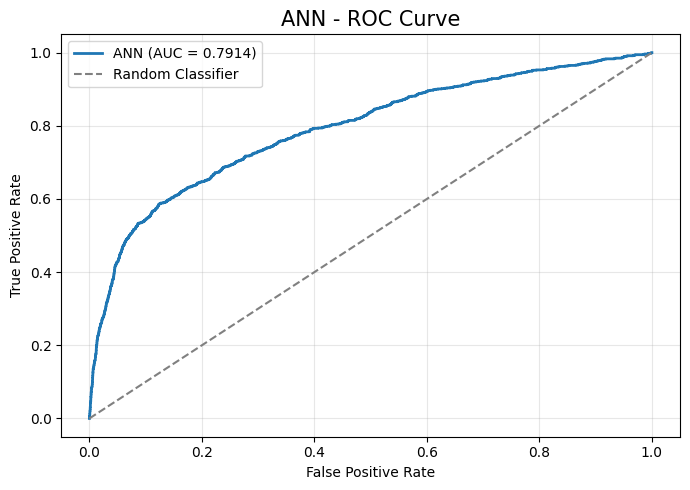

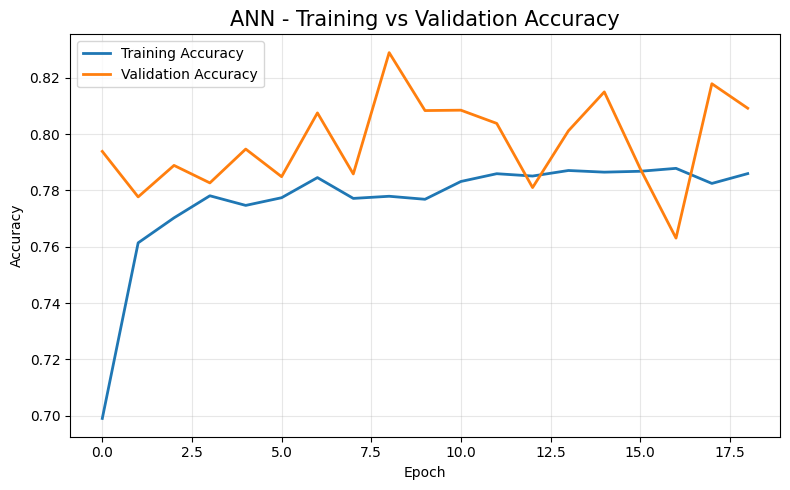

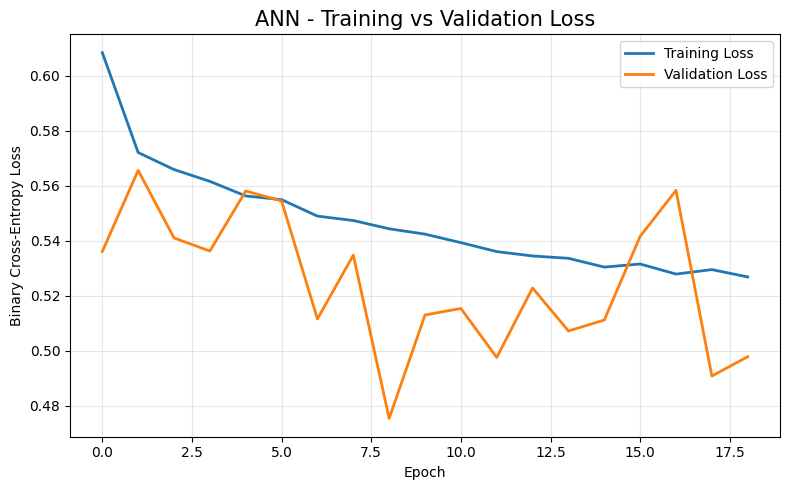

All four ANN graphs generated and saved successfully!


In [ ]:

# ANN Performance Visualizations

os.makedirs(GRAPH_PATH, exist_ok=True)

# --------------------------------
# 1. ANN CONFUSION MATRIX
# --------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    ann_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"],
    annot_kws={"size": 14}
)

plt.title("ANN - Confusion Matrix", fontsize=15)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_PATH, "ann_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# --------------------------------
# 2. ANN ROC CURVE
# --------------------------------

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ANN (AUC = {ann_roc_auc:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ANN - ROC Curve", fontsize=15)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_PATH, "ann_roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# --------------------------------
# 3. TRAINING VS VALIDATION ACCURACY
# --------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.title("ANN - Training vs Validation Accuracy", fontsize=15)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_PATH, "ann_training_validation_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# --------------------------------
# 4. TRAINING VS VALIDATION LOSS
# --------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.title("ANN - Training vs Validation Loss", fontsize=15)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_PATH, "ann_training_validation_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("All four ANN graphs generated and saved successfully!")


In [ ]:
# Save final ANN model
ann_model.save(os.path.join(MODEL_PATH, "ann_model.keras"))

# Prepare ANN results
ann_results = {
    "model_name": "Artificial Neural Network",
    "accuracy": float(ann_accuracy),
    "precision": float(ann_precision),
    "recall": float(ann_recall),
    "f1_score": float(ann_f1),
    "roc_auc": float(ann_roc_auc),

    "training_time_seconds": float(training_time),
    "epochs_completed": len(history.history["loss"]),

    "best_validation_loss": float(min(history.history["val_loss"])),
    "best_validation_accuracy": float(max(history.history["val_accuracy"])),

    "confusion_matrix": ann_cm.tolist(),

    "classification_report": classification_report(
        y_test,
        y_pred,
        target_names=["No Subscription", "Yes Subscription"],
        output_dict=True,
        zero_division=0
    ),

    "architecture": [
        "Input Layer: 50 features",
        "Dense Layer: 64 neurons, ReLU",
        "Dropout: 0.3",
        "Dense Layer: 32 neurons, ReLU",
        "Dropout: 0.2",
        "Output Layer: 1 neuron, Sigmoid"
    ],

    "hyperparameters": {
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "loss": "Binary Crossentropy",
        "batch_size": 32,
        "maximum_epochs": 100,
        "early_stopping_patience": 10,
        "threshold": 0.5
    }
}

# Save results as JSON
with open(os.path.join(RESULTS_PATH, "ann_results.json"), "w") as f:
    json.dump(ann_results, f, indent=4)

print("ANN model and evaluation results saved successfully!")

ANN model and evaluation results saved successfully!


In [ ]:
# Files that should exist
required_files = [
    os.path.join(MODEL_PATH, "ann_model.keras"),
    os.path.join(MODEL_PATH, "ann_best.keras"),
    os.path.join(RESULTS_PATH, "ann_results.json"),

    os.path.join(GRAPH_PATH, "ann_confusion_matrix.png"),
    os.path.join(GRAPH_PATH, "ann_roc_curve.png"),
    os.path.join(GRAPH_PATH, "ann_training_validation_accuracy.png"),
    os.path.join(GRAPH_PATH, "ann_training_validation_loss.png")
]

print("ANN FILE VERIFICATION")
print("=" * 50)

all_files_exist = True

for file_path in required_files:
    exists = os.path.exists(file_path)

    if exists:
        size_kb = os.path.getsize(file_path) / 1024
        print(f"✓ {os.path.basename(file_path)} — {size_kb:.2f} KB")
    else:
        print(f"✗ {os.path.basename(file_path)} — MISSING")
        all_files_exist = False

print("=" * 50)

# Verify JSON contents
with open(os.path.join(RESULTS_PATH, "ann_results.json"), "r") as f:
    saved_results = json.load(f)

print("\nSAVED ANN METRICS")
for metric in ["accuracy", "precision", "recall", "f1_score", "roc_auc"]:
    print(f"{metric}: {saved_results[metric]:.4f}")

print("\nAll required files exist:", all_files_exist)

ANN FILE VERIFICATION
✓ ann_model.keras — 92.18 KB
✓ ann_best.keras — 92.18 KB
✓ ann_results.json — 1.87 KB
✓ ann_confusion_matrix.png — 84.65 KB
✓ ann_roc_curve.png — 135.96 KB
✓ ann_training_validation_accuracy.png — 173.22 KB
✓ ann_training_validation_loss.png — 187.45 KB

SAVED ANN METRICS
accuracy: 0.8256
precision: 0.3548
recall: 0.5992
f1_score: 0.4457
roc_auc: 0.7914

All required files exist: True


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import json
import os

# Project paths
PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

rf_path = os.path.join(
    PROJECT_PATH, "results", "random_forest_results.json"
)

ann_path = os.path.join(
    PROJECT_PATH, "results", "ann_results.json"
)

# Load saved results
with open(rf_path, "r") as f:
    rf_results = json.load(f)

with open(ann_path, "r") as f:
    ann_results = json.load(f)

# Inspect both files
print("=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)
print(json.dumps(rf_results, indent=4))

print("\n" + "=" * 60)
print("ANN RESULTS")
print("=" * 60)
print(json.dumps(ann_results, indent=4))


RANDOM FOREST RESULTS
{
    "model_name": "Random Forest",
    "accuracy": 0.8780272033617162,
    "precision": 0.478176527643065,
    "recall": 0.4659735349716446,
    "f1_score": 0.4719961704164672,
    "roc_auc": 0.8002503512611667,
    "training_time": 10.205104112625122,
    "confusion_matrix": [
        [
            7447,
            538
        ],
        [
            565,
            493
        ]
    ],
    "classification_report": {
        "0": {
            "precision": 0.9294807788317524,
            "recall": 0.9326236693800877,
            "f1-score": 0.9310495717947115,
            "support": 7985.0
        },
        "1": {
            "precision": 0.478176527643065,
            "recall": 0.4659735349716446,
            "f1-score": 0.4719961704164672,
            "support": 1058.0
        },
        "accuracy": 0.8780272033617162,
        "macro avg": {
            "precision": 0.7038286532374087,
            "recall": 0.6992986021758661,
            "f1-score": 0.70

In [ ]:

import pandas as pd

# Create comparison dictionary using actual JSON results
comparison_data = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Training Time (seconds)"
    ],

    "Random Forest": [
        rf_results["accuracy"],
        rf_results["precision"],
        rf_results["recall"],
        rf_results["f1_score"],
        rf_results["roc_auc"],
        rf_results["training_time"]
    ],

    "ANN": [
        ann_results["accuracy"],
        ann_results["precision"],
        ann_results["recall"],
        ann_results["f1_score"],
        ann_results["roc_auc"],
        ann_results["training_time_seconds"]
    ]
}

# Create DataFrame
comparison_df = pd.DataFrame(comparison_data)

# Display formatted comparison
print("=" * 75)
print("RANDOM FOREST vs ARTIFICIAL NEURAL NETWORK")
print("=" * 75)

display(
    comparison_df.style.format({
        "Random Forest": "{:.4f}",
        "ANN": "{:.4f}"
    }).set_caption("Model Performance Comparison")
)


RANDOM FOREST vs ARTIFICIAL NEURAL NETWORK


,Metric,Random Forest,ANN
0,Accuracy,0.8780,0.8256
1,Precision,0.4782,0.3548
2,Recall,0.4660,0.5992
3,F1-Score,0.4720,0.4457
4,ROC-AUC,0.8003,0.7914
5,Training Time (seconds),10.2051,53.4214


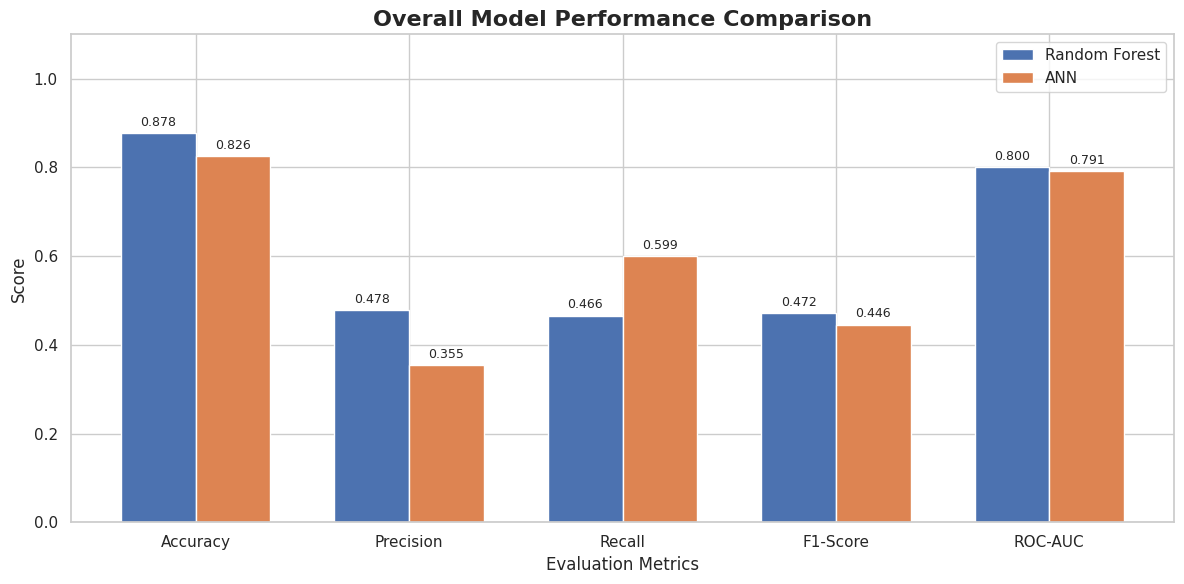

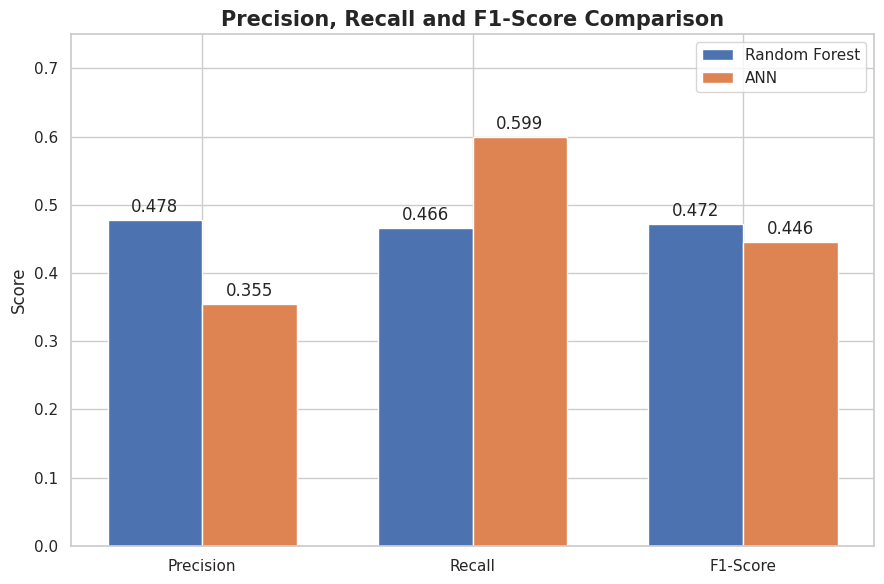

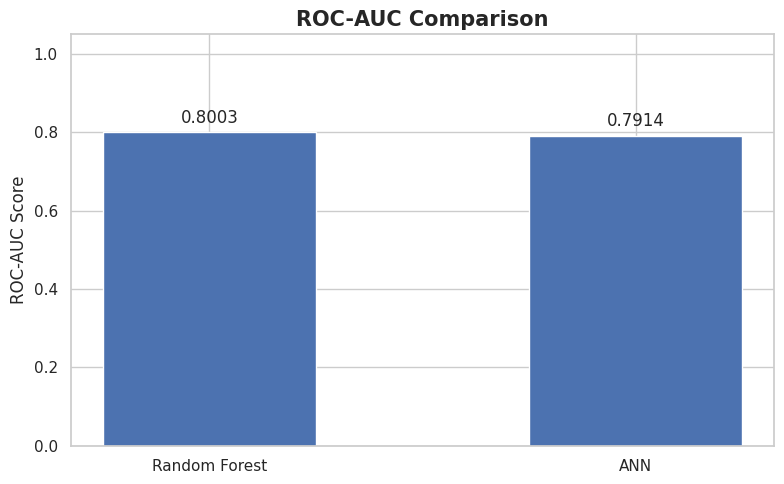

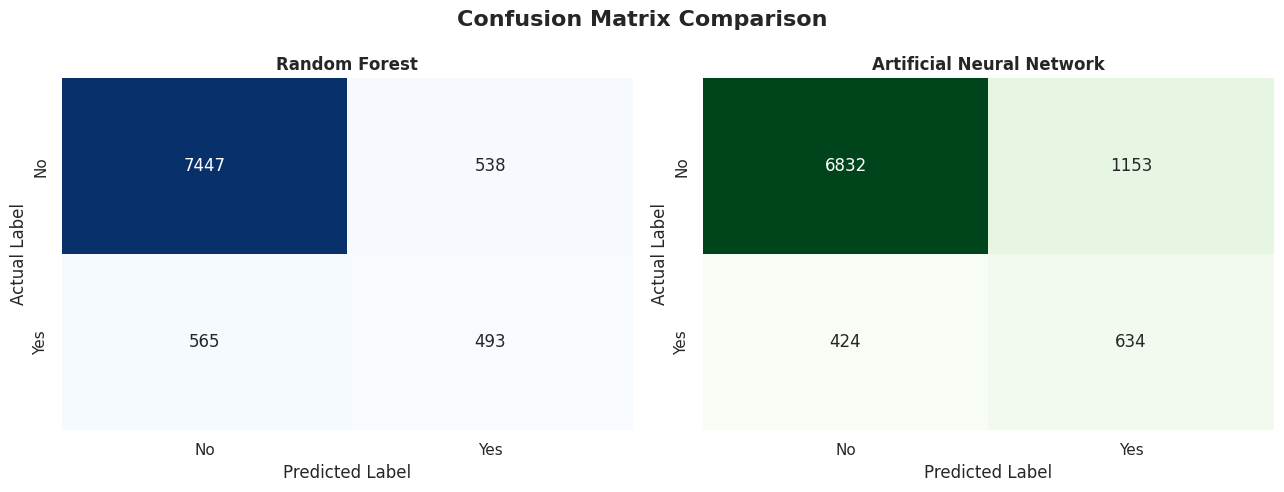


All four comparison visualizations generated successfully!


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# Graph directory
GRAPH_PATH = os.path.join(PROJECT_PATH, "results", "graphs")
os.makedirs(GRAPH_PATH, exist_ok=True)

# Model names
models = ["Random Forest", "ANN"]

# Extract actual metrics from saved results
accuracy = [
    rf_results["accuracy"],
    ann_results["accuracy"]
]

precision = [
    rf_results["precision"],
    ann_results["precision"]
]

recall = [
    rf_results["recall"],
    ann_results["recall"]
]

f1 = [
    rf_results["f1_score"],
    ann_results["f1_score"]
]

roc_auc = [
    rf_results["roc_auc"],
    ann_results["roc_auc"]
]

# Consistent visualization settings
sns.set_theme(style="whitegrid", context="notebook")

# ==========================================
# 1. OVERALL MODEL PERFORMANCE COMPARISON
# ==========================================

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

rf_scores = [
    rf_results["accuracy"],
    rf_results["precision"],
    rf_results["recall"],
    rf_results["f1_score"],
    rf_results["roc_auc"]
]

ann_scores = [
    ann_results["accuracy"],
    ann_results["precision"],
    ann_results["recall"],
    ann_results["f1_score"],
    ann_results["roc_auc"]
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(x - width/2, rf_scores, width, label="Random Forest")
bars2 = ax.bar(x + width/2, ann_scores, width, label="ANN")

ax.set_title("Overall Model Performance Comparison",
             fontsize=16, fontweight="bold")
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metrics")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.legend()

ax.bar_label(bars1, fmt="%.3f", padding=3, fontsize=9)
ax.bar_label(bars2, fmt="%.3f", padding=3, fontsize=9)

plt.tight_layout()
plt.savefig(
    os.path.join(GRAPH_PATH, "model_performance_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()


# ==========================================
# 2. PRECISION, RECALL AND F1 COMPARISON
# ==========================================

prf_metrics = ["Precision", "Recall", "F1-Score"]

rf_prf = [rf_results["precision"],
          rf_results["recall"],
          rf_results["f1_score"]]

ann_prf = [ann_results["precision"],
           ann_results["recall"],
           ann_results["f1_score"]]

x = np.arange(len(prf_metrics))

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(x - width/2, rf_prf, width, label="Random Forest")
bars2 = ax.bar(x + width/2, ann_prf, width, label="ANN")

ax.set_title("Precision, Recall and F1-Score Comparison",
             fontsize=15, fontweight="bold")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(prf_metrics)
ax.set_ylim(0, 0.75)
ax.legend()

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

plt.tight_layout()
plt.savefig(
    os.path.join(GRAPH_PATH, "precision_recall_f1_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()


# ==========================================
# 3. ROC-AUC COMPARISON
# ==========================================

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    models,
    roc_auc,
    width=0.5
)

ax.set_title("ROC-AUC Comparison",
             fontsize=15, fontweight="bold")
ax.set_ylabel("ROC-AUC Score")
ax.set_ylim(0, 1.05)

ax.bar_label(bars, fmt="%.4f", padding=4)

plt.tight_layout()
plt.savefig(
    os.path.join(GRAPH_PATH, "roc_auc_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()


# ==========================================
# 4. SIDE-BY-SIDE CONFUSION MATRICES
# ==========================================

rf_cm = np.array(rf_results["confusion_matrix"])
ann_cm = np.array(ann_results["confusion_matrix"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"],
    ax=axes[0],
    cbar=False
)

axes[0].set_title("Random Forest", fontweight="bold")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    ann_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"],
    ax=axes[1],
    cbar=False
)

axes[1].set_title("Artificial Neural Network", fontweight="bold")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

fig.suptitle(
    "Confusion Matrix Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    os.path.join(GRAPH_PATH, "model_confusion_matrix_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

print("\nAll four comparison visualizations generated successfully!")


In [ ]:

import joblib
import os

# Load previously saved processed data
processed_path = os.path.join(
    PROJECT_PATH, "models", "processed_data.pkl"
)

processed_data = joblib.load(processed_path)

print("PROCESSED DATA TYPE:", type(processed_data))

if isinstance(processed_data, dict):
    print("\nSAVED DATA KEYS:")
    for key, value in processed_data.items():
        print(key, ":", getattr(value, "shape", type(value)))

print("\n" + "=" * 60)
print("VALIDATION VARIABLES AVAILABLE IN NOTEBOOK")
print("=" * 60)

for name in sorted(globals()):
    if any(word in name.lower() for word in
           ["val", "valid", "x_train", "y_train"]):
        obj = globals()[name]
        print(name, ":", getattr(obj, "shape", type(obj)))


PROCESSED DATA TYPE: <class 'dict'>

SAVED DATA KEYS:
X_train_ml : (36168, 50)
X_test_ml : (9043, 50)
X_train_ann : (36168, 50)
X_test_ann : (9043, 50)
y_train : (36168,)
y_test : (9043,)
class_weights : <class 'dict'>

VALIDATION VARIABLES AVAILABLE IN NOTEBOOK
X_train_ann : (28934, 50)
X_train_ml : (36168, 50)
X_val_ann : (7234, 50)
value : <class 'dict'>
y_train : (36168,)
y_train_ann : (28934,)
y_val_ann : (7234,)


In [ ]:

print("ANN VALIDATION DATA CHECK")
print("=" * 45)

print("X_train_ann:", X_train_ann.shape)
print("X_val_ann:", X_val_ann.shape)
print("y_train_ann:", y_train_ann.shape)
print("y_val_ann:", y_val_ann.shape)

print("\nValidation dataset available:",
      len(X_val_ann) == len(y_val_ann))

print("Validation samples:", len(X_val_ann))


ANN VALIDATION DATA CHECK
X_train_ann: (28934, 50)
X_val_ann: (7234, 50)
y_train_ann: (28934,)
y_val_ann: (7234,)

Validation dataset available: True
Validation samples: 7234


In [ ]:
print("ANN VALIDATION DATA CHECK")
print("=" * 45)

print("X_train_ann:", X_train_ann.shape)
print("X_val_ann:", X_val_ann.shape)
print("y_train_ann:", y_train_ann.shape)
print("y_val_ann:", y_val_ann.shape)

print("\nValidation dataset available:",
      len(X_val_ann) == len(y_val_ann))

print("Validation samples:", len(X_val_ann))


ANN VALIDATION DATA CHECK
X_train_ann: (28934, 50)
X_val_ann: (7234, 50)
y_train_ann: (28934,)
y_val_ann: (7234,)

Validation dataset available: True
Validation samples: 7234


In [ ]:

import os
import numpy as np
from tensorflow.keras.models import load_model

# Load the best saved ANN model
ann_model_path = os.path.join(MODEL_PATH, "ann_best.keras")

if not os.path.exists(ann_model_path):
    raise FileNotFoundError(
        f"Saved ANN model not found: {ann_model_path}"
    )

ann_saved_model = load_model(ann_model_path)

print("Saved ANN model loaded successfully!")

# Generate probabilities on validation data
ann_val_probabilities = ann_saved_model.predict(
    X_val_ann,
    verbose=0
).ravel()

print("\nValidation Predictions Generated!")
print("Total predictions:", len(ann_val_probabilities))
print("Minimum probability:", ann_val_probabilities.min())
print("Maximum probability:", ann_val_probabilities.max())

print("\nFirst 10 predicted probabilities:")
print(ann_val_probabilities[:10])


Saved ANN model loaded successfully!

Validation Predictions Generated!
Total predictions: 7234
Minimum probability: 0.015809359
Maximum probability: 0.9901001

First 10 predicted probabilities:
[0.5953761  0.3387141  0.8589078  0.13814503 0.1931872  0.67488056
 0.7873536  0.49973327 0.55089194 0.09669858]


In [ ]:

import os
import numpy as np
from tensorflow.keras.models import load_model

# Load the best saved ANN model
ann_model_path = os.path.join(MODEL_PATH, "ann_best.keras")

if not os.path.exists(ann_model_path):
    raise FileNotFoundError(
        f"Saved ANN model not found: {ann_model_path}"
    )

ann_saved_model = load_model(ann_model_path)

print("Saved ANN model loaded successfully!")

# Generate probabilities on validation data
ann_val_probabilities = ann_saved_model.predict(
    X_val_ann,
    verbose=0
).ravel()

print("\nValidation Predictions Generated!")
print("Total predictions:", len(ann_val_probabilities))
print("Minimum probability:", ann_val_probabilities.min())
print("Maximum probability:", ann_val_probabilities.max())

print("\nFirst 10 predicted probabilities:")
print(ann_val_probabilities[:10])


Saved ANN model loaded successfully!

Validation Predictions Generated!
Total predictions: 7234
Minimum probability: 0.015809359
Maximum probability: 0.9901001

First 10 predicted probabilities:
[0.5953761  0.3387141  0.8589078  0.13814503 0.1931872  0.67488056
 0.7873536  0.49973327 0.55089194 0.09669858]


In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import pandas as pd
import numpy as np

# Check that validation probabilities are available
assert len(ann_val_probabilities) == len(y_val_ann)

# Thresholds to compare
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for threshold in thresholds:

    # Convert probabilities into Yes/No predictions
    predictions = (ann_val_probabilities >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val_ann, predictions),
        "Precision": precision_score(y_val_ann, predictions, zero_division=0),
        "Recall": recall_score(y_val_ann, predictions, zero_division=0),
        "F1-Score": f1_score(y_val_ann, predictions, zero_division=0)
    })

# Display comparison
threshold_results = pd.DataFrame(results)

print("ANN VALIDATION THRESHOLD COMPARISON")
print("=" * 65)

print(threshold_results.round(4).to_string(index=False))

# Identify threshold with highest F1-score
best_index = threshold_results["F1-Score"].idxmax()

best_threshold = threshold_results.loc[best_index, "Threshold"]

print("\nBest Threshold based on Validation F1-Score:", best_threshold)
print("Best Validation F1-Score:",
      threshold_results.loc[best_index, "F1-Score"])


ANN VALIDATION THRESHOLD COMPARISON
 Threshold  Accuracy  Precision  Recall  F1-Score
      0.30    0.5734     0.1921  0.8262    0.3118
      0.35    0.6594     0.2231  0.7707    0.3461
      0.40    0.7297     0.2609  0.7151    0.3823
      0.45    0.7859     0.3087  0.6702    0.4227
      0.50    0.8290     0.3656  0.6288    0.4624
      0.55    0.8547     0.4144  0.5863    0.4856
      0.60    0.8690     0.4487  0.5272    0.4848

Best Threshold based on Validation F1-Score: 0.55
Best Validation F1-Score: 0.4855604503181596


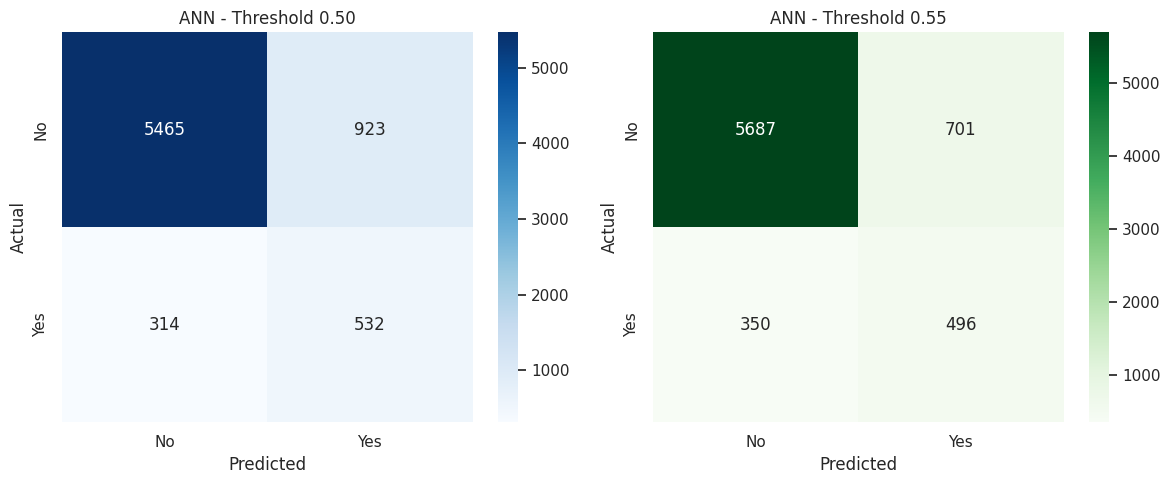

Threshold 0.50:
 [[5465  923]
 [ 314  532]]

Threshold 0.55:
 [[5687  701]
 [ 350  496]]


In [ ]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions at both thresholds
pred_050 = (ann_val_probabilities >= 0.50).astype(int)
pred_055 = (ann_val_probabilities >= 0.55).astype(int)

# Calculate confusion matrices
cm_050 = confusion_matrix(y_val_ann, pred_050)
cm_055 = confusion_matrix(y_val_ann, pred_055)

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_050, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"], ax=axes[0]
)
axes[0].set_title("ANN - Threshold 0.50")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_055, annot=True, fmt="d", cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"], ax=axes[1]
)
axes[1].set_title("ANN - Threshold 0.55")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

print("Threshold 0.50:\n", cm_050)
print("\nThreshold 0.55:\n", cm_055)


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Generate test probabilities
ann_test_probabilities = ann_saved_model.predict(
    X_test_ann,
    verbose=0
).ravel()

# Original baseline predictions (0.50)
ann_test_pred_050 = (
    ann_test_probabilities >= 0.50
).astype(int)

# Tuned predictions (0.55)
ann_test_pred_055 = (
    ann_test_probabilities >= 0.55
).astype(int)

# Calculate metrics for both thresholds
for threshold, predictions in [
    (0.50, ann_test_pred_050),
    (0.55, ann_test_pred_055)
]:

    print("\n" + "=" * 55)
    print(f"ANN TEST RESULTS - THRESHOLD {threshold}")
    print("=" * 55)

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("Precision:",
          precision_score(y_test, predictions, zero_division=0))

    print("Recall:",
          recall_score(y_test, predictions, zero_division=0))

    print("F1-Score:",
          f1_score(y_test, predictions, zero_division=0))

    print("ROC-AUC:",
          roc_auc_score(y_test, ann_test_probabilities))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

print("\nClassification Report - Tuned ANN:")
print(classification_report(
    y_test,
    ann_test_pred_055,
    target_names=["No Subscription", "Yes Subscription"]
))



ANN TEST RESULTS - THRESHOLD 0.5
Accuracy: 0.8256109698109034
Precision: 0.35478455512031337
Recall: 0.5992438563327032
F1-Score: 0.4456942003514939
ROC-AUC: 0.7914339031241233

Confusion Matrix:
[[6832 1153]
 [ 424  634]]

ANN TEST RESULTS - THRESHOLD 0.55
Accuracy: 0.8534778281543736
Precision: 0.40683879972086534
Recall: 0.5510396975425331
F1-Score: 0.46808510638297873
ROC-AUC: 0.7914339031241233

Confusion Matrix:
[[7135  850]
 [ 475  583]]

Classification Report - Tuned ANN:
                  precision    recall  f1-score   support

 No Subscription       0.94      0.89      0.92      7985
Yes Subscription       0.41      0.55      0.47      1058

        accuracy                           0.85      9043
       macro avg       0.67      0.72      0.69      9043
    weighted avg       0.88      0.85      0.86      9043



In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define project paths
PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")

# Create directories if needed
os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(RESULTS_PATH, exist_ok=True)

print("Project Path:", PROJECT_PATH)
print("Model Path:", MODEL_PATH)
print("Project Exists:", os.path.exists(PROJECT_PATH))
print("Models Folder Ready!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project Path: /content/drive/MyDrive/Marketing-Campaign-Prediction
Model Path: /content/drive/MyDrive/Marketing-Campaign-Prediction/models
Project Exists: True
Models Folder Ready!


In [ ]:

import json
import os


# Define model directory
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
os.makedirs(MODEL_PATH, exist_ok=True)

print("Model directory:", MODEL_PATH)

# Save ANN threshold tuning results
tuning_results = {
    "model_name": "Artificial Neural Network",
    "original_threshold": 0.50,
    "tuned_threshold": 0.55,
    "validation_best_f1": 0.4855604503181596,

    "test_results": {
        "accuracy": 0.8534778281543736,
        "precision": 0.40683879972086534,
        "recall": 0.5510396975425331,
        "f1_score": 0.46808510638297873,
        "roc_auc": 0.7914339031241233
    }
}

save_path = os.path.join(
    MODEL_PATH,
    "ann_threshold_tuning_results.json"
)

with open(save_path, "w") as file:
    json.dump(tuning_results, file, indent=4)

print("Threshold tuning results saved successfully!")
print("Saved at:", save_path)


Model directory: /content/drive/MyDrive/Marketing-Campaign-Prediction/models
Threshold tuning results saved successfully!
Saved at: /content/drive/MyDrive/Marketing-Campaign-Prediction/models/ann_threshold_tuning_results.json


In [ ]:

import json
import os

# Restore Random Forest results
rf_path = os.path.join(
    PROJECT_PATH, "results", "random_forest_results.json"
)

with open(rf_path, "r") as f:
    rf_results = json.load(f)

# Restore ANN results
ann_path = os.path.join(
    PROJECT_PATH, "results", "ann_results.json"
)

with open(ann_path, "r") as f:
    ann_results = json.load(f)

print("Both model results restored successfully!")

print("\nRandom Forest:", rf_results["model_name"])
print("ANN:", ann_results["model_name"])


Both model results restored successfully!

Random Forest: Random Forest
ANN: Artificial Neural Network



## Final Model Comparison and Selection

### Random Forest vs Artificial Neural Network

Both models were evaluated using Accuracy, Precision, Recall, F1-Score and ROC-AUC.

**Random Forest:**
- Higher accuracy (87.80%).
- Higher precision (47.82%).
- Higher F1-score (47.20%).
- Higher ROC-AUC (80.03%).
- Lower training time.

**Artificial Neural Network:**
- Higher recall at the original threshold (59.92%).
- Better ability to identify potential subscribers.
- Tuned threshold of 0.55 improved the balance between precision and recall.

### Final Observation

Random Forest provides better overall balanced performance based on the original test metrics.

ANN provides higher recall, making it useful when identifying more potential subscribers is a priority.

The final model selection will consider the business objective of marketing campaign effectiveness prediction.


In [ ]:

import json
import os

# Ensure project directories exist
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")
os.makedirs(RESULTS_PATH, exist_ok=True)

# Final model comparison
model_comparison = {

    "project": "Marketing Campaign Effectiveness Prediction",

    "baseline_comparison": {
        "random_forest": rf_results,
        "ann": ann_results
    },

    "ann_threshold_tuning": {
        "original_threshold": 0.50,
        "tuned_threshold": 0.55,
        "validation_best_f1": 0.4855604503181596,
        "test_results": {
            "accuracy": 0.8534778281543736,
            "precision": 0.40683879972086534,
            "recall": 0.5510396975425331,
            "f1_score": 0.46808510638297873,
            "roc_auc": 0.7914339031241233
        }
    },

    "observations": [
        "Random Forest achieved higher baseline accuracy.",
        "Random Forest achieved higher baseline precision.",
        "ANN achieved higher baseline recall.",
        "Random Forest achieved higher baseline F1-score.",
        "Random Forest achieved higher baseline ROC-AUC.",
        "ANN threshold tuning improved its test precision and F1-score.",
        "ANN retained higher recall than Random Forest after tuning."
    ],

    "selected_model": "Random Forest",

    "selection_reason": (
        "Random Forest was selected because it achieved the "
        "highest accuracy, precision, F1-score and ROC-AUC "
        "among the evaluated configurations. It also required "
        "less training time. ANN remains a useful alternative "
        "when identifying more potential subscribers is the "
        "primary business priority."
    )
}

# Save JSON
comparison_file = os.path.join(
    RESULTS_PATH,
    "model_comparison.json"
)

with open(comparison_file, "w") as f:
    json.dump(model_comparison, f, indent=4)

print("Model comparison saved successfully!")
print("Location:", comparison_file)


Model comparison saved successfully!
Location: /content/drive/MyDrive/Marketing-Campaign-Prediction/results/model_comparison.json


In [ ]:

import os
import json

# Paths to verify
files_to_check = [
    "models/random_forest_model.pkl",
    "models/ann_best.keras",
    "models/ann_model.keras",
    "models/preprocessor.pkl",
    "models/scaler.pkl",
    "models/processed_data.pkl",
    "models/ann_threshold_tuning_results.json",
    "results/random_forest_results.json",
    "results/ann_results.json",
    "results/model_comparison.json",
    "results/graphs/model_performance_comparison.png",
    "results/graphs/precision_recall_f1_comparison.png",
    "results/graphs/roc_auc_comparison.png",
    "results/graphs/model_confusion_matrix_comparison.png"
]

print("PROJECT FILE VERIFICATION")
print("=" * 50)

for file in files_to_check:
    path = os.path.join(PROJECT_PATH, file)
    status = "FOUND" if os.path.exists(path) else "MISSING"
    print(f"{file}: {status}")

# Verify comparison JSON
comparison_path = os.path.join(
    PROJECT_PATH, "results", "model_comparison.json"
)

with open(comparison_path, "r") as f:
    comparison_data = json.load(f)

print("\nSelected Model:", comparison_data["selected_model"])
print("Verification completed.")


PROJECT FILE VERIFICATION
models/random_forest_model.pkl: FOUND
models/ann_best.keras: FOUND
models/ann_model.keras: FOUND
models/preprocessor.pkl: FOUND
models/scaler.pkl: FOUND
models/processed_data.pkl: FOUND
models/ann_threshold_tuning_results.json: FOUND
results/random_forest_results.json: FOUND
results/ann_results.json: FOUND
results/model_comparison.json: FOUND
results/graphs/model_performance_comparison.png: FOUND
results/graphs/precision_recall_f1_comparison.png: FOUND
results/graphs/roc_auc_comparison.png: FOUND
results/graphs/model_confusion_matrix_comparison.png: FOUND

Selected Model: Random Forest
Verification completed.


In [ ]:
import joblib
import os

preprocessor_path = os.path.join(
    PROJECT_PATH, "models", "preprocessor.pkl"
)

preprocessor = joblib.load(preprocessor_path)

print("Preprocessor type:", type(preprocessor))
print("\nPreprocessor details:")
print(preprocessor)

print("\nFeature names after preprocessing:")
print(preprocessor.get_feature_names_out())


Preprocessor type: <class 'sklearn.compose._column_transformer.ColumnTransformer'>

Preprocessor details:
ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['job', 'marital', 'education', 'default',
                                  'housing', 'loan', 'contact', 'month',
                                  'poutcome']),
                                ('num', 'passthrough',
                                 ['age', 'balance', 'day', 'campaign', 'pdays',
                                  'previous'])])

Feature names after preprocessing:
['cat__job_admin.' 'cat__job_blue-collar' 'cat__job_entrepreneur'
 'cat__job_housemaid' 'cat__job_management' 'cat__job_retired'
 'cat__job_self-employed' 'cat__job_services' 'cat__job_student'
 'cat__job_technician' 'cat__job_unemployed' 'cat__job_unknown'
 'cat__marital_divorced' 'cat__marital_married' 'cat__marital_single'
 'cat__education_primary' 'cat__education_secondary'
 'cat__education

In [ ]:

import os

app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "w") as f:
    f.write("# Marketing Campaign Effectiveness Prediction - Streamlit App\n")

print("app.py created successfully!")
print("Location:", app_path)


app.py created successfully!
Location: /content/drive/MyDrive/Marketing-Campaign-Prediction/app.py


In [ ]:

app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import json
import os

# ---------------- PAGE CONFIGURATION ----------------

st.set_page_config(
    page_title="MarketingIQ | Campaign Intelligence",
    page_icon="📊",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ---------------- PROJECT PATHS ----------------

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")
GRAPHS_PATH = os.path.join(RESULTS_PATH, "graphs")

# ---------------- LOAD SAVED MODEL ----------------

@st.cache_resource
def load_model():
    model = joblib.load(
        os.path.join(MODEL_PATH, "random_forest_model.pkl")
    )
    preprocessor = joblib.load(
        os.path.join(MODEL_PATH, "preprocessor.pkl")
    )
    return model, preprocessor

model, preprocessor = load_model()

# ---------------- LOAD RESULTS ----------------

with open(os.path.join(RESULTS_PATH, "random_forest_results.json")) as f:
    rf_results = json.load(f)

with open(os.path.join(RESULTS_PATH, "ann_results.json")) as f:
    ann_results = json.load(f)

with open(os.path.join(RESULTS_PATH, "model_comparison.json")) as f:
    comparison = json.load(f)

# ---------------- CUSTOM STYLING ----------------

st.markdown("""
<style>
    @import url('https://fonts.cdnfonts.com/css/ragellan');
       stApp,
.stApp * {
        font-family: 'Ragellan', serif !important;
    }

    .stApp {
        background-color: #F5F7FB;
    }

    [data-testid="stSidebar"] {
        background-color: #111827;
    }

    [data-testid="stSidebar"] * {
        color: #F9FAFB;
    }

    .main-title {
        font-size: 2.2rem;
        font-weight: 700;
        color: #172554;
        margin-bottom: 0.2rem;
    }

    .sub-title {
        color: #64748B;
        font-size: 1rem;
        margin-bottom: 1.5rem;
    }

    .section-title {
        color: #172554;
        font-size: 1.35rem;
        font-weight: 700;
        margin-top: 1rem;
    }

    div[data-testid="stMetric"] {
        background: white;
        border: 1px solid #E2E8F0;
        padding: 18px;
        border-radius: 12px;
    }

    .stButton button {
        background-color: #2563EB;
        color: white;
        border-radius: 8px;
        border: none;
        padding: 0.55rem 1.2rem;
        font-weight: 600;
    }

    .stButton button:hover {
        background-color: #1D4ED8;
        color: white;
    }
</style>
""", unsafe_allow_html=True)

# ---------------- SIDEBAR NAVIGATION ----------------

with st.sidebar:
    st.html(f"""
    <div class="brand-logo">
        {logo_svg}
        <div class="brand-name">
            Campaign<span>Mind</span>
        </div>
    </div>
    """)

    st.divider()

    page = st.radio(
        "NAVIGATION",
        [
            "Dashboard",
            "Predict Subscription",
            "EDA Insights",
            "Model Comparison"
        ]
    )

    st.divider()
    st.caption("Machine Learning + Deep Learning")

# ---------------- PAGE HEADER ----------------

st.markdown(
    '<div class="main-title">Marketing Campaign Intelligence</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="sub-title">Understand campaign performance and predict customer subscription behaviour.</div>',
    unsafe_allow_html=True
)
'''

with open(os.path.join(PROJECT_PATH, "app.py"), "w") as f:
    f.write(app_code)

print("Application foundation written to app.py successfully!")
print("File size:", os.path.getsize(os.path.join(PROJECT_PATH, "app.py")), "bytes")


Application foundation written to app.py successfully!
File size: 3369 bytes


In [ ]:

import os
import py_compile
import importlib.util

APP_PATH = os.path.join(PROJECT_PATH, "app.py")

# Check Python syntax
py_compile.compile(APP_PATH, doraise=True)
print("1. Python syntax: PASSED")

# Check required libraries
libraries = ["streamlit", "pandas", "numpy", "sklearn", "joblib"]

print("\n2. Library availability:")
for library in libraries:
    status = "INSTALLED" if importlib.util.find_spec(library) else "MISSING"
    print(f"{library}: {status}")

print("\n3. App file size:", os.path.getsize(APP_PATH), "bytes")


1. Python syntax: PASSED

2. Library availability:
streamlit: MISSING
pandas: INSTALLED
numpy: INSTALLED
sklearn: INSTALLED
joblib: INSTALLED

3. App file size: 3369 bytes


In [ ]:

!pip install streamlit -q

import streamlit as st

print("Streamlit installed successfully!")
print("Version:", st.__version__)


Streamlit installed successfully!
Version: 1.67.0


In [ ]:

app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import json
import os

# ==========================================
# PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="CampaignMind | Campaign Intelligence",
    page_icon="📊",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ==========================================
# PROJECT PATHS
# ==========================================

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")
GRAPHS_PATH = os.path.join(RESULTS_PATH, "graphs")

# ==========================================
# LOAD MODEL AND PREPROCESSOR
# ==========================================

@st.cache_resource
def load_model():
    model = joblib.load(
        os.path.join(MODEL_PATH, "random_forest_model.pkl")
    )
    preprocessor = joblib.load(
        os.path.join(MODEL_PATH, "preprocessor.pkl")
    )
    return model, preprocessor

model, preprocessor = load_model()

# ==========================================
# LOAD MODEL RESULTS
# ==========================================

def load_json(filename):
    path = os.path.join(RESULTS_PATH, filename)
    with open(path, "r") as file:
        return json.load(file)

rf_results = load_json("random_forest_results.json")
ann_results = load_json("ann_results.json")
comparison = load_json("model_comparison.json")

# ==========================================
# CUSTOM STYLING
# ==========================================

st.markdown("""
<style>

@import url('https://fonts.cdnfonts.com/css/ragellan');
html, body, [class*="css"], .stApp,
.stApp p, .stApp span, .stApp label,
.stApp button, .stApp input, .stApp textarea,
.stApp h1, .stApp h2, .stApp h3, .stApp h4  {
    font-family: 'Ragellan', serif !important;

[data-testid="stHeader"] {
    background: transparent;
}

[data-testid="stSidebar"] {
    background: linear-gradient(180deg, #0B1733 0%, #101D43 100%);
}

[data-testid="stSidebar"] * {
    color: #F8FAFC;
}

[data-testid="stSidebar"] hr {
    border-color: #33466F;
}

.brand-logo {
    display: flex;
    align-items: center;
    gap: 12px;
    margin: 8px 0 10px 0;
}

.brand-icon {
    .brand-icon {
    width: 52px;
    height: 52px;
    flex-shrink: 0;
    display: block;
    overflow: visible;
}


.brand-name {
    font-size: 25px;
    font-weight: 800;
    letter-spacing: -1px;
    color: #FFFFFF;
}

.brand-name span {
    color: #818CF8;
}

.brand-tagline {
    color: #B9C7E8;
    font-size: 11px;
    letter-spacing: 2px;
    margin-top: 3px;
}

.main-brand {
    display: flex;
    align-items: center;
    gap: 15px;
    margin-bottom: 5px;
}

.main-brand .brand-name {
    color: #101D43;
    font-size: 42px;
}

.main-brand .brand-name span {
    color: #6542D8;
}

.page-subtitle {
    color: #64748B;
    font-size: 15px;
    margin: 5px 0 28px 0;
}

.section-heading {
    color: #172554;
    font-size: 21px;
    font-weight: 700;
    margin: 22px 0 12px 0;
}

div[data-testid="stMetric"] {
    background: #FFFFFF;
    border: 1px solid #DFE6FA;
    border-radius: 14px;
    padding: 20px 18px;
    min-height: 112px;
    box-shadow: 0 3px 12px rgba(30, 50, 100, 0.04);
}

div[data-testid="stMetricLabel"] {
    color: #64748B;
    font-size: 14px;
    font-weight: 500;
}

div[data-testid="stMetricValue"] {
    color: #14234A;
    font-size: 27px;
    font-weight: 800;
}

div[data-testid="stRadio"] label {
    font-weight: 500;
}

.block-container {
    padding-top: 2.5rem;
    padding-bottom: 2rem;
}

</style>
""", unsafe_allow_html=True)

# ==========================================
# CONSISTENT CAMPAIGNMIND LOGO
# ==========================================

logo_svg = """
<svg class="brand-icon"
     viewBox="0 0 100 100"
     xmlns="http://www.w3.org/2000/svg"
     role="img"
     aria-label="CampaignMind logo">

    <path
        d="M76 25 A34 34 0 1 0 77 76"
        fill="none"
        stroke="#A9D6E5"
        stroke-width="9"
        stroke-linecap="round"
    />

    <path
        d="M40 67 L57 48 L68 54 L86 30"
        fill="none"
        stroke="#A9D6E5"
        stroke-width="6"
        stroke-linecap="round"
        stroke-linejoin="round"
    />

    <path
        d="M72 30 H86 V44"
        fill="none"
        stroke="#A9D6E5"
        stroke-width="6"
        stroke-linecap="round"
        stroke-linejoin="round"
    />
</svg>
"""

# ==========================================
# SIDEBAR
# ==========================================

with st.sidebar:

    st.markdown(
        f"""
        <div style="padding:12px 4px 18px 4px;">
            <div class="brand-logo">
                {logo_svg}
                <div class="brand-name">
                    Campaign<span>Mind</span>
                </div>
            </div>
            <div class="brand-tagline">CAMPAIGN INTELLIGENCE</div>
        </div>
        """,
        unsafe_allow_html=True
    )

    st.divider()

    st.markdown(
        "<p style='color:#AFC0E5;font-size:13px;"
        "font-weight:700;letter-spacing:1px;'>NAVIGATION</p>",
        unsafe_allow_html=True
    )

    page = st.radio(
        "Navigation",
        [
            "Dashboard",
            "Predict Subscription",
            "EDA Insights",
            "Model Comparison"
        ],
        label_visibility="collapsed"
    )

# ==========================================
# MAIN HEADER
# ==========================================

st.markdown(
    f"""
    <div class="main-brand">
        {logo_svg}
        <div class="brand-name">
            Campaign<span>Mind</span>
        </div>
    </div>
    <div class="page-subtitle">
        Understand campaign performance and predict customer
        subscription behaviour.
    </div>
    """,
    unsafe_allow_html=True
)

# ==========================================
# DASHBOARD PAGE
# ==========================================

if page == "Dashboard":

    # Overview cards
    st.markdown(
        '<div class="section-heading">Campaign Overview</div>',
        unsafe_allow_html=True
    )

    col1, col2, col3, col4 = st.columns(4)

    with col1:
        st.metric("Total Records", "45,211")

    with col2:
        st.metric("Input Features", "15")

    with col3:
        st.metric("Models Evaluated", "2")

    with col4:
        st.metric("Selected Model", "Random Forest")

    # Random Forest performance
    st.markdown(
        '<div class="section-heading">'
        'Random Forest – Performance</div>',
        unsafe_allow_html=True
    )

    col1, col2, col3, col4 = st.columns(4)

    with col1:
        st.metric(
            "Accuracy",
            f"{rf_results['accuracy'] * 100:.2f}%"
        )

    with col2:
        st.metric(
            "Precision",
            f"{rf_results['precision'] * 100:.2f}%"
        )

    with col3:
        st.metric(
            "Recall",
            f"{rf_results['recall'] * 100:.2f}%"
        )

    with col4:
        st.metric(
            "F1 Score",
            f"{rf_results['f1_score'] * 100:.2f}%"
        )

# ==========================================
# OTHER PAGES - TO BE DEVELOPED
# ==========================================

elif page == "Predict Subscription":
    st.markdown("## Predict Customer Subscription")
    st.info("Prediction form will be developed next.")

elif page == "EDA Insights":
    st.markdown("## Exploratory Data Analysis")
    st.info("Project EDA visualizations will be added next.")

elif page == "Model Comparison":
    st.markdown("## Model Comparison")
    st.info("Detailed model comparison will be added next.")
'''

app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "w") as file:
    file.write(app_code)

print("CampaignMind app.py updated successfully!")
print("Location:", app_path)
print("File size:", os.path.getsize(app_path), "bytes")


CampaignMind app.py updated successfully!
Location: /content/drive/MyDrive/Marketing-Campaign-Prediction/app.py
File size: 7818 bytes


In [ ]:

import py_compile
import os

app_path = os.path.join(PROJECT_PATH, "app.py")

py_compile.compile(app_path, doraise=True)

print("Syntax check: PASSED")
print("File exists:", os.path.exists(app_path))
print("Application size:", os.path.getsize(app_path), "bytes")


Syntax check: PASSED
File exists: True
Application size: 7818 bytes


In [ ]:

prediction_code = r'''
elif page == "Predict Subscription":

    st.markdown("## Customer Subscription Prediction")
    st.write(
        "Enter the customer's details below to estimate "
        "their likelihood of subscribing to a term deposit."
    )

    st.markdown("---")

    with st.form("customer_prediction_form"):

        st.markdown("### Personal Information")

        col1, col2, col3 = st.columns(3)

        with col1:
            age = st.number_input(
                "Age",
                min_value=18,
                max_value=100,
                value=35
            )

        with col2:
            job = st.selectbox(
                "Job",
                [
                    "admin.", "blue-collar", "entrepreneur",
                    "housemaid", "management", "retired",
                    "self-employed", "services", "student",
                    "technician", "unemployed", "unknown"
                ]
            )

        with col3:
            marital = st.selectbox(
                "Marital Status",
                ["married", "single", "divorced"]
            )

        col1, col2 = st.columns(2)

        with col1:
            education = st.selectbox(
                "Education",
                ["primary", "secondary", "tertiary", "unknown"]
            )

        with col2:
            default = st.selectbox(
                "Has Credit in Default?",
                ["no", "yes"]
            )

        st.markdown("---")
        st.markdown("### Financial Information")

        col1, col2, col3 = st.columns(3)

        with col1:
            balance = st.number_input(
                "Average Yearly Balance (€)",
                min_value=-100000,
                max_value=1000000,
                value=1000
            )

        with col2:
            housing = st.selectbox(
                "Housing Loan?",
                ["no", "yes"]
            )

        with col3:
            loan = st.selectbox(
                "Personal Loan?",
                ["no", "yes"]
            )

        st.markdown("---")
        st.markdown("### Campaign Information")

        col1, col2, col3 = st.columns(3)

        with col1:
            contact = st.selectbox(
                "Contact Communication Type",
                ["cellular", "telephone", "unknown"]
            )

        with col2:
            day = st.number_input(
                "Last Contact Day",
                min_value=1,
                max_value=31,
                value=15
            )

        with col3:
            month = st.selectbox(
                "Last Contact Month",
                [
                    "jan", "feb", "mar", "apr", "may",
                    "jun", "jul", "aug", "sep", "oct",
                    "nov", "dec"
                ]
            )

        col1, col2, col3 = st.columns(3)

        with col1:
            campaign = st.number_input(
                "Contacts During This Campaign",
                min_value=1,
                max_value=100,
                value=2
            )

        with col2:
            pdays = st.number_input(
                "Days Since Previous Contact (-1 if never contacted)",
                min_value=-1,
                max_value=999,
                value=-1
            )

        with col3:
            previous = st.number_input(
                "Contacts Before This Campaign",
                min_value=0,
                max_value=100,
                value=0
            )

        poutcome = st.selectbox(
            "Previous Campaign Outcome",
            ["unknown", "failure", "other", "success"]
        )

        submitted = st.form_submit_button(
            "Predict Subscription",
            use_container_width=True
        )

    if submitted:

        customer_data = pd.DataFrame([{
            "age": age,
            "job": job,
            "marital": marital,
            "education": education,
            "default": default,
            "balance": balance,
            "housing": housing,
            "loan": loan,
            "contact": contact,
            "day": day,
            "month": month,
            "campaign": campaign,
            "pdays": pdays,
            "previous": previous,
            "poutcome": poutcome
        }])

        try:
            transformed_data = preprocessor.transform(customer_data)

            prediction = model.predict(transformed_data)[0]
            probabilities = model.predict_proba(transformed_data)[0]

            subscription_probability = float(probabilities[1])

            st.markdown("---")
            st.markdown("### Prediction Result")

            if prediction == 1:
                st.success("Likely to Subscribe")
            else:
                st.warning("Unlikely to Subscribe")

            st.metric(
                "Subscription Probability",
                f"{subscription_probability * 100:.2f}%"
            )

            st.progress(subscription_probability)

            st.caption(
                "Probability is the Random Forest model's estimate, "
                "not a guarantee of customer behaviour."
            )

        except Exception as e:
            st.error(f"Prediction failed: {e}")
'''

app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as f:
    existing_code = f.read()

old_placeholder = '''elif page == "Predict Subscription":
    st.markdown("## Predict Customer Subscription")
    st.info("Prediction form will be developed next.")'''

if old_placeholder not in existing_code:
    print("Placeholder not found. No changes made.")
else:
    existing_code = existing_code.replace(
        old_placeholder,
        prediction_code.strip(),
        1
    )

    with open(app_path, "w") as f:
        f.write(existing_code)

    print("Prediction page added successfully!")
    print("Updated file:", app_path)


Prediction page added successfully!
Updated file: /content/drive/MyDrive/Marketing-Campaign-Prediction/app.py


In [ ]:

import py_compile

py_compile.compile(
    os.path.join(PROJECT_PATH, "app.py"),
    doraise=True
)

print("Prediction page syntax: PASSED")


Prediction page syntax: PASSED


In [ ]:

import os

graphs_path = os.path.join(PROJECT_PATH, "results", "graphs")

print("SAVED PROJECT GRAPHS")
print("=" * 45)

for filename in sorted(os.listdir(graphs_path)):
    if filename.lower().endswith((".png", ".jpg", ".jpeg")):
        print(filename)


SAVED PROJECT GRAPHS
age_distribution.png
ann_confusion_matrix.png
ann_roc_curve.png
ann_training_validation_accuracy.png
ann_training_validation_loss.png
correlation_heatmap.png
job_distribution.png
model_confusion_matrix_comparison.png
model_performance_comparison.png
precision_recall_f1_comparison.png
rf_confusion_matrix.png
rf_feature_importance.png
rf_roc_curve.png
roc_auc_comparison.png
subscription_by_contact.png
subscription_by_education.png
subscription_by_housing.png
subscription_by_job.png
subscription_by_marital.png
subscription_by_month.png
subscription_by_poutcome.png
target_distribution.png


In [ ]:

eda_code = r'''
elif page == "EDA Insights":

    st.markdown("## Exploratory Data Analysis")
    st.write(
        "Explore customer demographics, campaign patterns "
        "and relationships in the Bank Marketing dataset."
    )

    def show_graph(title, filename, description):
        graph_path = os.path.join(GRAPHS_PATH, filename)

        st.markdown(f"### {title}")
        st.caption(description)

        if os.path.exists(graph_path):
            st.image(graph_path, use_container_width=True)
        else:
            st.warning(f"Graph not found: {filename}")

    # --------------------------------------
    # CUSTOMER DISTRIBUTION
    # --------------------------------------

    st.markdown("---")
    st.markdown("### 1. Customer Distribution")

    col1, col2 = st.columns(2)

    with col1:
        show_graph(
            "Age Distribution",
            "age_distribution.png",
            "Distribution of customers across different age groups."
        )

    with col2:
        show_graph(
            "Job Distribution",
            "job_distribution.png",
            "Distribution of customers across occupational categories."
        )

    col1, col2 = st.columns(2)

    with col1:
        show_graph(
            "Subscription Distribution",
            "target_distribution.png",
            "Distribution of customers who subscribed and did not subscribe."
        )

    with col2:
        show_graph(
            "Correlation Heatmap",
            "correlation_heatmap.png",
            "Relationships between numerical variables in the dataset."
        )

    # --------------------------------------
    # CAMPAIGN INSIGHTS
    # --------------------------------------

    st.markdown("---")
    st.markdown("### 2. Campaign Insights")

    campaign_graphs = [
        (
            "Subscription by Contact Type",
            "subscription_by_contact.png",
            "Subscription outcomes across communication channels."
        ),
        (
            "Subscription by Education",
            "subscription_by_education.png",
            "Subscription patterns across education levels."
        ),
        (
            "Subscription by Housing Loan",
            "subscription_by_housing.png",
            "Relationship between housing loans and subscription outcomes."
        ),
        (
            "Subscription by Job",
            "subscription_by_job.png",
            "Subscription outcomes across occupational categories."
        ),
        (
            "Subscription by Marital Status",
            "subscription_by_marital.png",
            "Subscription patterns across marital status categories."
        ),
        (
            "Subscription by Month",
            "subscription_by_month.png",
            "Variation in subscription outcomes across campaign months."
        ),
        (
            "Subscription by Previous Outcome",
            "subscription_by_poutcome.png",
            "Subscription patterns based on previous campaign outcomes."
        )
    ]

    for i in range(0, len(campaign_graphs), 2):

        col1, col2 = st.columns(2)

        with col1:
            title, filename, description = campaign_graphs[i]
            show_graph(title, filename, description)

        if i + 1 < len(campaign_graphs):
            with col2:
                title, filename, description = campaign_graphs[i + 1]
                show_graph(title, filename, description)

'''

app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as f:
    existing_code = f.read()

old_placeholder = '''elif page == "EDA Insights":
    st.markdown("## Exploratory Data Analysis")
    st.info("Project EDA visualizations will be added next.")'''

if old_placeholder not in existing_code:
    print("EDA placeholder not found. No changes made.")
else:
    existing_code = existing_code.replace(
        old_placeholder,
        eda_code.strip(),
        1
    )

    with open(app_path, "w") as f:
        f.write(existing_code)

    print("EDA Insights page added successfully!")
    print("Graphs configured:", 11)
    print("Updated app.py:", app_path)


EDA Insights page added successfully!
Graphs configured: 11
Updated app.py: /content/drive/MyDrive/Marketing-Campaign-Prediction/app.py


In [ ]:

import py_compile

py_compile.compile(
    os.path.join(PROJECT_PATH, "app.py"),
    doraise=True
)

print("EDA page syntax: PASSED")

import py_compile

py_compile.compile(
    os.path.join(PROJECT_PATH, "app.py"),
    doraise=True
)

print("EDA page syntax: PASSED")


EDA page syntax: PASSED
EDA page syntax: PASSED


In [ ]:

comparison_code = '''
elif page == "Model Comparison":
    st.markdown("## Model Performance Comparison")
    st.markdown(
        "Evaluate the performance of Random Forest and Artificial Neural Network "
        "using the project's saved evaluation results."
    )

    # Overall model metrics
    st.markdown("### Performance Metrics")

    metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc"]

    col1, col2 = st.columns(2)

    with col1:
        st.markdown("#### Random Forest")
        for metric in metric_names:
            value = rf_results.get(metric)
            if value is not None:
                st.metric(metric.replace("_", " ").title(), f"{value:.4f}")

    with col2:
        st.markdown("#### Artificial Neural Network")
        for metric in metric_names:
            value = ann_results.get(metric)
            if value is not None:
                st.metric(metric.replace("_", " ").title(), f"{value:.4f}")

    st.divider()

    # Model comparison visualizations
    st.markdown("### Direct Model Comparison")

    comparison_graphs = [
        (
            "Overall Performance",
            "model_performance_comparison.png",
            "Comparison of the main evaluation metrics."
        ),
        (
            "Precision, Recall and F1 Score",
            "precision_recall_f1_comparison.png",
            "Comparison of classification performance."
        ),
        (
            "ROC-AUC Comparison",
            "roc_auc_comparison.png",
            "Comparison of the models' ability to distinguish between classes."
        ),
        (
            "Confusion Matrix Comparison",
            "model_confusion_matrix_comparison.png",
            "Comparison of correct and incorrect predictions."
        )
    ]

    for title, filename, description in comparison_graphs:
        graph_path = os.path.join(GRAPHS_PATH, filename)
        st.markdown(f"#### {title}")
        st.caption(description)

        if os.path.exists(graph_path):
            st.image(graph_path, use_container_width=True)
        else:
            st.warning(f"Graph not found: {filename}")

    st.divider()

    # Individual model analysis
    st.markdown("### Individual Model Analysis")

    rf_tab, ann_tab = st.tabs(["Random Forest", "Artificial Neural Network"])

    with rf_tab:
        for title, filename in [
            ("Confusion Matrix", "rf_confusion_matrix.png"),
            ("ROC Curve", "rf_roc_curve.png"),
            ("Feature Importance", "rf_feature_importance.png")
        ]:
            graph_path = os.path.join(GRAPHS_PATH, filename)
            st.markdown(f"#### {title}")
            if os.path.exists(graph_path):
                st.image(graph_path, use_container_width=True)
            else:
                st.warning(f"Graph not found: {filename}")

    with ann_tab:
        for title, filename in [
            ("Confusion Matrix", "ann_confusion_matrix.png"),
            ("ROC Curve", "ann_roc_curve.png"),
            ("Training and Validation Accuracy", "ann_training_validation_accuracy.png"),
            ("Training and Validation Loss", "ann_training_validation_loss.png")
        ]:
            graph_path = os.path.join(GRAPHS_PATH, filename)
            st.markdown(f"#### {title}")
            if os.path.exists(graph_path):
                st.image(graph_path, use_container_width=True)
            else:
                st.warning(f"Graph not found: {filename}")

    st.divider()

    # Final model selection
    st.markdown("### Selected Model")
    st.markdown(
        "**Random Forest** is selected as the final prediction model. "
        "It achieved the strongest overall balance across accuracy, precision, "
        "F1 score and ROC-AUC in the evaluated configurations. "
        "The ANN achieved higher recall, so it identified more actual subscribers, "
        "but its overall F1 score was slightly lower."
    )

    st.caption(
        "Note: The metrics above show the saved baseline evaluation results. "
        "The separately tuned ANN threshold is not mixed into this baseline comparison."
    )
'''

old_placeholder = '''elif page == "Model Comparison":
    st.markdown("## Model Comparison")
    st.info("Model comparison visualizations will be added next.")'''

app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as file:
    app_code = file.read()

if old_placeholder in app_code:
    app_code = app_code.replace(old_placeholder, comparison_code.strip())
    with open(app_path, "w") as file:
        file.write(app_code)
    print("Model Comparison page added successfully!")
else:
    print("Placeholder not found. Do not replace anything yet.")


Placeholder not found. Do not replace anything yet.


In [ ]:
app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if "Model Comparison" in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 15)

        print(f"\n--- Lines {start + 1} to {end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


--- Lines 246 to 263 ---
246:             "Dashboard",

247:             "Predict Subscription",

248:             "EDA Insights",

249:             "Model Comparison"

250:         ],

251:         label_visibility="collapsed"

252:     )

253: 

254: # ==========================================

255: # MAIN HEADER

256: # ==========================================

257: 

258: st.markdown(

259:     f"""

260:     <div class="main-brand">

261:         {logo_svg}

262:         <div class="brand-name">

263:             Campaign<span>Mind</span>


--- Lines 646 to 651 ---
646:                 title, filename, description = campaign_graphs[i + 1]

647:                 show_graph(title, filename, description)

648: 

649: elif page == "Model Comparison":

650:     st.markdown("## Model Comparison")

651:     st.info("Detailed model comparison will be added next.")


--- Lines 647 to 651 ---
647:                 show_graph(title, filename, description)

648: 

649: elif page == "Model C

In [ ]:

comparison_code = '''
elif page == "Model Comparison":
    st.markdown("## Model Performance Comparison")
    st.markdown(
        "Evaluate Random Forest and Artificial Neural Network "
        "using the project's saved evaluation results."
    )

    st.markdown("### Performance Metrics")

    col1, col2 = st.columns(2)

    with col1:
        st.markdown("#### Random Forest")
        for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
            value = rf_results.get(metric)
            if value is not None:
                st.metric(metric.replace("_", " ").title(), f"{value:.4f}")

    with col2:
        st.markdown("#### Artificial Neural Network")
        for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
            value = ann_results.get(metric)
            if value is not None:
                st.metric(metric.replace("_", " ").title(), f"{value:.4f}")

    st.divider()
    st.markdown("### Direct Model Comparison")

    comparison_graphs = [
        ("Overall Performance", "model_performance_comparison.png"),
        ("Precision, Recall and F1 Score", "precision_recall_f1_comparison.png"),
        ("ROC-AUC Comparison", "roc_auc_comparison.png"),
        ("Confusion Matrix Comparison", "model_confusion_matrix_comparison.png")
    ]

    for title, filename in comparison_graphs:
        st.markdown(f"#### {title}")
        graph_path = os.path.join(GRAPHS_PATH, filename)
        if os.path.exists(graph_path):
            st.image(graph_path, use_container_width=True)
        else:
            st.warning(f"Graph not found: {filename}")

    st.divider()
    st.markdown("### Individual Model Analysis")

    rf_tab, ann_tab = st.tabs(["Random Forest", "Artificial Neural Network"])

    with rf_tab:
        for title, filename in [
            ("Confusion Matrix", "rf_confusion_matrix.png"),
            ("ROC Curve", "rf_roc_curve.png"),
            ("Feature Importance", "rf_feature_importance.png")
        ]:
            st.markdown(f"#### {title}")
            graph_path = os.path.join(GRAPHS_PATH, filename)
            if os.path.exists(graph_path):
                st.image(graph_path, use_container_width=True)
            else:
                st.warning(f"Graph not found: {filename}")

    with ann_tab:
        for title, filename in [
            ("Confusion Matrix", "ann_confusion_matrix.png"),
            ("ROC Curve", "ann_roc_curve.png"),
            ("Training and Validation Accuracy", "ann_training_validation_accuracy.png"),
            ("Training and Validation Loss", "ann_training_validation_loss.png")
        ]:
            st.markdown(f"#### {title}")
            graph_path = os.path.join(GRAPHS_PATH, filename)
            if os.path.exists(graph_path):
                st.image(graph_path, use_container_width=True)
            else:
                st.warning(f"Graph not found: {filename}")

    st.divider()
    st.markdown("### Final Model Selection")
    st.markdown(
        "**Random Forest** is selected as the final prediction model "
        "because it achieved the strongest overall balance across accuracy, "
        "precision, F1 score and ROC-AUC. ANN achieved higher recall, "
        "but its overall F1 score was slightly lower."
    )

    st.caption(
        "Metrics shown above are baseline evaluation results. "
        "The separately tuned ANN threshold is not mixed into this comparison."
    )
'''

old_section = '''elif page == "Model Comparison":
    st.markdown("## Model Comparison")
    st.info("Detailed model comparison will be added next.")'''

app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as file:
    app_code = file.read()

if old_section in app_code:
    app_code = app_code.replace(old_section, comparison_code.strip())
    with open(app_path, "w") as file:
        file.write(app_code)
    print("Model Comparison page added successfully!")
else:
    print("Exact section not found. No changes made.")


Model Comparison page added successfully!


In [ ]:
import py_compile

py_compile.compile(app_path, doraise=True)
print("Syntax check: PASSED")

Syntax check: PASSED


In [ ]:
import os

required_files = [
    "app.py",
    "models/random_forest_model.pkl",
    "models/preprocessor.pkl",
    "results/random_forest_results.json",
    "results/ann_results.json",
    "results/model_comparison.json",
]

required_graphs = [
    "age_distribution.png",
    "job_distribution.png",
    "target_distribution.png",
    "correlation_heatmap.png",
    "subscription_by_contact.png",
    "subscription_by_education.png",
    "subscription_by_housing.png",
    "subscription_by_job.png",
    "subscription_by_marital.png",
    "subscription_by_month.png",
    "subscription_by_poutcome.png",
    "model_performance_comparison.png",
    "precision_recall_f1_comparison.png",
    "roc_auc_comparison.png",
    "model_confusion_matrix_comparison.png",
    "rf_confusion_matrix.png",
    "rf_roc_curve.png",
    "rf_feature_importance.png",
    "ann_confusion_matrix.png",
    "ann_roc_curve.png",
    "ann_training_validation_accuracy.png",
    "ann_training_validation_loss.png",
]

print("APPLICATION FILE CHECK")
print("=" * 40)

for file in required_files:
    path = os.path.join(PROJECT_PATH, file)
    print(("FOUND  " if os.path.exists(path) else "MISSING ") + file)

print("\nGRAPH FILE CHECK")
print("=" * 40)

for file in required_graphs:
    path = os.path.join(PROJECT_PATH, "results", "graphs", file)
    print(("FOUND  " if os.path.exists(path) else "MISSING ") + file)

APPLICATION FILE CHECK
FOUND  app.py
FOUND  models/random_forest_model.pkl
FOUND  models/preprocessor.pkl
FOUND  results/random_forest_results.json
FOUND  results/ann_results.json
FOUND  results/model_comparison.json

GRAPH FILE CHECK
FOUND  age_distribution.png
FOUND  job_distribution.png
FOUND  target_distribution.png
FOUND  correlation_heatmap.png
FOUND  subscription_by_contact.png
FOUND  subscription_by_education.png
FOUND  subscription_by_housing.png
FOUND  subscription_by_job.png
FOUND  subscription_by_marital.png
FOUND  subscription_by_month.png
FOUND  subscription_by_poutcome.png
FOUND  model_performance_comparison.png
FOUND  precision_recall_f1_comparison.png
FOUND  roc_auc_comparison.png
FOUND  model_confusion_matrix_comparison.png
FOUND  rf_confusion_matrix.png
FOUND  rf_roc_curve.png
FOUND  rf_feature_importance.png
FOUND  ann_confusion_matrix.png
FOUND  ann_roc_curve.png
FOUND  ann_training_validation_accuracy.png
FOUND  ann_training_validation_loss.png


In [ ]:
!streamlit run "{PROJECT_PATH}/app.py" --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
import time

time.sleep(5)

with open("/content/streamlit.log", "r") as file:
    print(file.read())



2026-11-22 10:39:51.751 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.21.67.76:8501




In [ ]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!tail -40 /content/streamlit.log

  Network URL: http://172.28.0.12:8501
  External URL: http://34.21.67.76:8501

2026-11-22 10:41:26.128 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use4b2-2mznmss4re1uk-b.us-east4.prod.r.colab.dev, host=m-s-use4b2-2mznmss4re1uk.us-east4-b.c.codatalab-user-runtimes.internal:8007
2026-11-22 10:41:28.277 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use4b2-2mznmss4re1uk-b.us-east4.prod.r.colab.dev, host=m-s-use4b2-2mznmss4re1uk.us-east4-b.c.codatalab-user-runtimes.internal:8007
2026-11-22 10:41:31.524 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use4b2-2mznmss4re1uk-b.us-east4.prod.r.colab.dev, host=m-s-use4b2-2mznmss4re1uk.us-east4-b.c.codatalab-user-runtimes.internal:8007
2026-11-22 10:41:34.594 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use4b2-2mznmss4re1uk-b.us-east4.prod.r.colab.dev, host=

In [ ]:
!fuser -k 8501/tcp

8501/tcp:            19089


In [ ]:
!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as file:
    lines = file.readlines()

keywords = ["logo_svg", "main-brand", "st.radio", "brand-name"]

for keyword in keywords:
    print(f"\n{'='*20} {keyword} {'='*20}")

    for i, line in enumerate(lines):
        if keyword in line:
            start = max(0, i - 5)
            end = min(len(lines), i + 12)

            for j in range(start, end):
                print(f"{j+1}: {lines[j]}")


==================== logo_svg ====================
183: 

184: # ==========================================

185: # CONSISTENT CAMPAIGNMIND LOGO

186: # ==========================================

187: 

188: logo_svg = """

189: <svg class="brand-icon" viewBox="0 0 64 64"

190:      xmlns="http://www.w3.org/2000/svg">

191:     <defs>

192:         <linearGradient id="brandGradient" x1="0" y1="1" x2="1" y2="0">

193:             <stop offset="0%" stop-color="#1685FF"/>

194:             <stop offset="100%" stop-color="#7542E8"/>

195:         </linearGradient>

196:     </defs>

197:     <rect x="7" y="39" width="11" height="18" rx="2"

198:           fill="url(#brandGradient)"/>

199:     <rect x="25" y="27" width="11" height="30" rx="2"

219: 

220:     st.markdown(

221:         f"""

222:         <div style="padding:12px 4px 18px 4px;">

223:             <div class="brand-logo">

224:                 {logo_svg}

225:                 <div class="brand-name">

226:                 

In [ ]:
app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as file:
    lines = file.readlines()

print("===== SIDEBAR + NAVIGATION =====")
for i in range(210, 254):
    print(f"{i+1}: {lines[i]}", end="")

print("\n===== MAIN HEADER =====")
for i in range(254, 274):
    print(f"{i+1}: {lines[i]}", end="")

print("\n===== CSS NAVIGATION STYLES =====")
for i, line in enumerate(lines):
    if "sidebar" in line.lower() or "radio" in line.lower():
        print(f"{i+1}: {line}", end="")

===== SIDEBAR + NAVIGATION =====
211: </svg>
212: """
213: 
214: # ==========================================
215: # SIDEBAR
216: # ==========================================
217: 
218: with st.sidebar:
219: 
220:     st.markdown(
221:         f"""
222:         <div style="padding:12px 4px 18px 4px;">
223:             <div class="brand-logo">
224:                 {logo_svg}
225:                 <div class="brand-name">
226:                     Campaign<span>Mind</span>
227:                 </div>
228:             </div>
229:             <div class="brand-tagline">CAMPAIGN INTELLIGENCE</div>
230:         </div>
231:         """,
232:         unsafe_allow_html=True
233:     )
234: 
235:     st.divider()
236: 
237:     st.markdown(
238:         "<p style='color:#AFC0E5;font-size:13px;"
239:         "font-weight:700;letter-spacing:1px;'>NAVIGATION</p>",
240:         unsafe_allow_html=True
241:     )
242: 
243:     page = st.radio(
244:         "Navigation",
245:         [
246:             

In [ ]:

app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as file:
    app_code = file.read()

# 1. Replace the sidebar and navigation section
start = app_code.index("with st.sidebar:")
end = app_code.index(
    "# ==========================================\n# MAIN HEADER",
    start
)

new_sidebar = '''
from textwrap import dedent

# CUSTOM SIDEBAR NAVIGATION STYLING
st.markdown("""
<style>
[data-testid="stSidebar"] button {
    width: 100%;
    min-height: 46px;
    border-radius: 10px;
    text-align: left;
    font-size: 14px;
    font-weight: 600;
    transition: all 0.2s ease;
}

[data-testid="stSidebar"] button[kind="secondary"] {
    background: transparent;
    color: #DCE6FF;
    border: 1px solid transparent;
}

[data-testid="stSidebar"] button[kind="secondary"]:hover {
    background: #263B69;
    border-color: #526B9C;
    color: white;
}

[data-testid="stSidebar"] button[kind="primary"] {
    background: linear-gradient(110deg, #3158C9, #6542D8);
    color: white;
    border: 1px solid #8195FF;
}
</style>
""", unsafe_allow_html=True)

# SIDEBAR
with st.sidebar:

    st.markdown(
        dedent(f"""
        <div style="padding:12px 4px 18px 4px;">
            <div class="brand-logo">
                {logo_svg}
                <div class="brand-name">
                    Campaign<span>Mind</span>
                </div>
            </div>
            <div class="brand-tagline">CAMPAIGN INTELLIGENCE</div>
        </div>
        """).strip(),
        unsafe_allow_html=True
    )

    st.divider()

    st.markdown(
        "<p style='color:#AFC0E5;font-size:13px;"
        "font-weight:700;letter-spacing:1px;'>NAVIGATION</p>",
        unsafe_allow_html=True
    )

    navigation_pages = [
        "Dashboard",
        "Predict Subscription",
        "EDA Insights",
        "Model Comparison"
    ]

    if "selected_page" not in st.session_state:
        st.session_state.selected_page = "Dashboard"

    for page_name in navigation_pages:
        is_active = st.session_state.selected_page == page_name

        if st.button(
            page_name,
            key="nav_" + page_name.replace(" ", "_").lower(),
            type="primary" if is_active else "secondary",
            use_container_width=True
        ):
            st.session_state.selected_page = page_name
            st.rerun()

    page = st.session_state.selected_page

'''

app_code = app_code[:start] + new_sidebar + app_code[end:]

# 2. Replace the main header section
header_marker = "# MAIN HEADER"
header_start = app_code.index("st.markdown(", app_code.index(header_marker))
header_end = app_code.index(
    "# ==========================================",
    header_start
)

new_header = '''
st.markdown(
    dedent(f"""
    <div class="main-brand">
        {logo_svg}
        <div class="brand-name">
            Campaign<span>Mind</span>
        </div>
    </div>
    <div class="page-subtitle">
        Understand campaign performance and predict customer
        subscription behaviour.
    </div>
    """).strip(),
    unsafe_allow_html=True
)

'''

app_code = app_code[:header_start] + new_header + app_code[header_end:]

# 3. Save updated app
with open(app_path, "w") as file:
    file.write(app_code)

print("Header and navigation updated successfully!")


Header and navigation updated successfully!


In [ ]:
import py_compile

py_compile.compile(app_path, doraise=True)
print("Syntax check: PASSED")

Syntax check: PASSED


In [ ]:
!fuser -k 8501/tcp


8501/tcp:            20711


In [ ]:
!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as file:
    app_code = file.read()

# Fix sidebar branding
old_sidebar = '''    st.markdown(
        dedent(f"""
        <div style="padding:12px 4px 18px 4px;">
            <div class="brand-logo">
                {logo_svg}
                <div class="brand-name">
                    Campaign<span>Mind</span>
                </div>
            </div>
            <div class="brand-tagline">CAMPAIGN INTELLIGENCE</div>
        </div>
        """).strip(),
        unsafe_allow_html=True
    )'''

new_sidebar = '''    st.html(f"""
    <div style="padding:12px 4px 18px 4px;">
        <div class="brand-logo">
            {logo_svg}
            <div class="brand-name">
                Campaign<span>Mind</span>
            </div>
        </div>
        <div class="brand-tagline">CAMPAIGN INTELLIGENCE</div>
    </div>
    """)'''

# Fix main header and subtitle
old_header = '''st.markdown(
    dedent(f"""
    <div class="main-brand">
        {logo_svg}
        <div class="brand-name">
            Campaign<span>Mind</span>
        </div>
    </div>
    <div class="page-subtitle">
        Understand campaign performance and predict customer
        subscription behaviour.
    </div>
    """).strip(),
    unsafe_allow_html=True
)'''

new_header = '''st.html(f"""
<div class="main-brand">
    {logo_svg}
    <div class="brand-name">
        Campaign<span>Mind</span>
    </div>
</div>
<div class="page-subtitle">
    Explore customer trends, compare predictive models, and predict
    customer subscription likelihood.
</div>
""")'''

if old_sidebar in app_code and old_header in app_code:
    app_code = app_code.replace(old_sidebar, new_sidebar, 1)
    app_code = app_code.replace(old_header, new_header, 1)

    with open(app_path, "w") as file:
        file.write(app_code)

    print("Sidebar and main header fixed!")
    print("Subtitle updated!")
else:
    print("One or both sections did not match. No changes saved.")

Sidebar and main header fixed!
Subtitle updated!


In [ ]:
import py_compile
py_compile.compile(app_path, doraise=True)
print("Syntax check: PASSED")

Syntax check: PASSED


In [ ]:
with open(app_path, "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if 'elif page == "Model Comparison":' in line:
        for j in range(i, min(i + 115, len(lines))):
            print(f"{j+1}: {lines[j]}", end="")
        break

694: elif page == "Model Comparison":
695:     st.markdown("## Model Performance Comparison")
696:     st.markdown(
697:         "Evaluate Random Forest and Artificial Neural Network "
698:         "using the project's saved evaluation results."
699:     )
700: 
701:     st.markdown("### Performance Metrics")
702: 
703:     col1, col2 = st.columns(2)
704: 
705:     with col1:
706:         st.markdown("#### Random Forest")
707:         for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
708:             value = rf_results.get(metric)
709:             if value is not None:
710:                 st.metric(metric.replace("_", " ").title(), f"{value:.4f}")
711: 
712:     with col2:
713:         st.markdown("#### Artificial Neural Network")
714:         for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
715:             value = ann_results.get(metric)
716:             if value is not None:
717:                 st.metric(metric.replace("_", " ").title(), f"{val

In [ ]:

app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as file:
    app_code = file.read()

start_marker = '    st.markdown("### Individual Model Analysis")'
end_marker = '    st.markdown("### Final Model Selection")'

start = app_code.index(start_marker)
end = app_code.index(end_marker, start)

new_analysis = '''    st.markdown("### Explore Individual Model Insights")
    st.markdown(
        "Select a machine learning model to explore its evaluation results."
    )

    selected_model = st.selectbox(
        "Choose Model",
        ["Random Forest", "Artificial Neural Network"],
        key="insights_model_selector"
    )

    if selected_model == "Random Forest":
        st.markdown("#### Random Forest Analysis")

        model_graphs = [
            ("Confusion Matrix", "rf_confusion_matrix.png"),
            ("ROC Curve", "rf_roc_curve.png"),
            ("Feature Importance", "rf_feature_importance.png")
        ]

    else:
        st.markdown("#### Artificial Neural Network Analysis")

        model_graphs = [
            ("Confusion Matrix", "ann_confusion_matrix.png"),
            ("ROC Curve", "ann_roc_curve.png"),
            ("Training and Validation Accuracy",
             "ann_training_validation_accuracy.png"),
            ("Training and Validation Loss",
             "ann_training_validation_loss.png")
        ]

    for title, filename in model_graphs:
        st.markdown(f"#### {title}")

        graph_path = os.path.join(GRAPHS_PATH, filename)

        if os.path.exists(graph_path):
            st.image(graph_path, use_container_width=True)
        else:
            st.warning(f"Graph not found: {filename}")

    st.divider()
'''

app_code = (
    app_code[:start]
    + new_analysis
    + app_code[end:]
)

with open(app_path, "w") as file:
    file.write(app_code)

print("Individual model selector added successfully!")


Individual model selector added successfully!


In [ ]:
import py_compile

py_compile.compile(app_path, doraise=True)
print("Syntax check: PASSED")


Syntax check: PASSED


In [ ]:
import py_compile
import time

# Verify app syntax
py_compile.compile(app_path, doraise=True)
print("Syntax check: PASSED")

# Stop previous Streamlit server
!fuser -k 8501/tcp

# Restart application
!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

time.sleep(5)

print("CampaignMind restart initiated.")

Syntax check: PASSED
8501/tcp:            22582
CampaignMind restart initiated.


In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
with open(app_path, "r") as file:
    lines = file.readlines()

print("===== DASHBOARD SECTION =====")

for i, line in enumerate(lines):
    if 'if page == "Dashboard":' in line:
        for j in range(i, min(i + 100, len(lines))):
            print(f"{j+1}: {lines[j]}", end="")
        break

print("\n===== METRIC CSS =====")

for i, line in enumerate(lines):
    if "stMetric" in line or "metric" in line.lower():
        print(f"{i+1}: {line}", end="")

===== DASHBOARD SECTION =====
323: if page == "Dashboard":
324: 
325:     # Overview cards
326:     st.markdown(
327:         '<div class="section-heading">Campaign Overview</div>',
328:         unsafe_allow_html=True
329:     )
330: 
331:     col1, col2, col3, col4 = st.columns(4)
332: 
333:     with col1:
334:         st.metric("Total Records", "45,211")
335: 
336:     with col2:
337:         st.metric("Input Features", "15")
338: 
339:     with col3:
340:         st.metric("Models Evaluated", "2")
341: 
342:     with col4:
343:         st.metric("Selected Model", "Random Forest")
344: 
345:     # Random Forest performance
346:     st.markdown(
347:         '<div class="section-heading">'
348:         'Random Forest – Performance</div>',
349:         unsafe_allow_html=True
350:     )
351: 
352:     col1, col2, col3, col4 = st.columns(4)
353: 
354:     with col1:
355:         st.metric(
356:             "Accuracy",
357:             f"{rf_results['accuracy'] * 100:.2f}%"
358:         )

In [ ]:
import json

# Check metric names
print("RANDOM FOREST METRIC KEYS:")
print(rf_results.keys())

print("\nANN METRIC KEYS:")
print(ann_results.keys())

# Inspect existing CSS
with open(app_path, "r") as file:
    lines = file.readlines()

print("\n===== METRIC CSS (LINES 145–180) =====")
for i in range(144, 180):
    print(f"{i+1}: {lines[i]}", end="")

RANDOM FOREST METRIC KEYS:
dict_keys(['model_name', 'accuracy', 'precision', 'recall', 'f1_score', 'roc_auc', 'training_time', 'confusion_matrix', 'classification_report', 'model_parameters'])

ANN METRIC KEYS:
dict_keys(['model_name', 'accuracy', 'precision', 'recall', 'f1_score', 'roc_auc', 'training_time_seconds', 'epochs_completed', 'best_validation_loss', 'best_validation_accuracy', 'confusion_matrix', 'classification_report', 'architecture', 'hyperparameters'])

===== METRIC CSS (LINES 145–180) =====
145:     color: #172554;
146:     font-size: 21px;
147:     font-weight: 700;
148:     margin: 22px 0 12px 0;
149: }
150: 
151: div[data-testid="stMetric"] {
152:     background: #FFFFFF;
153:     border: 1px solid #DFE6FA;
154:     border-radius: 14px;
155:     padding: 20px 18px;
156:     min-height: 112px;
157:     box-shadow: 0 3px 12px rgba(30, 50, 100, 0.04);
158: }
159: 
160: div[data-testid="stMetricLabel"] {
161:     color: #64748B;
162:     font-size: 14px;
163:     font-we

In [ ]:

app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r") as file:
    app_code = file.read()

# ==========================================
# 1. REPLACE DASHBOARD SECTION
# ==========================================

start_marker = 'if page == "Dashboard":'
end_marker = 'elif page == "Predict Subscription":'

start = app_code.index(start_marker)
end = app_code.index(end_marker, start)

new_dashboard = '''if page == "Dashboard":

    st.markdown(
        '<div class="section-heading">Campaign Overview</div>',
        unsafe_allow_html=True
    )

    # MODEL SELECTOR
    selected_model = st.selectbox(
        "Select model to explore",
        ["Random Forest", "Artificial Neural Network"],
        key="dashboard_model_selector"
    )

    # Select corresponding saved results
    selected_results = (
        rf_results
        if selected_model == "Random Forest"
        else ann_results
    )

    # Overview cards
    col1, col2, col3, col4 = st.columns(4)

    with col1:
        st.metric("Total Records", "45,211")

    with col2:
        st.metric("Input Features", "15")

    with col3:
        st.metric("Models Evaluated", "2")

    with col4:
        st.metric("Selected Model", selected_model)

    # Dynamic model performance
    st.markdown(
        f'<div class="section-heading">'
        f'{selected_model} – Performance</div>',
        unsafe_allow_html=True
    )

    col1, col2, col3, col4 = st.columns(4)

    with col1:
        st.metric(
            "Accuracy",
            f"{selected_results['accuracy'] * 100:.2f}%"
        )

    with col2:
        st.metric(
            "Precision",
            f"{selected_results['precision'] * 100:.2f}%"
        )

    with col3:
        st.metric(
            "Recall",
            f"{selected_results['recall'] * 100:.2f}%"
        )

    with col4:
        st.metric(
            "F1 Score",
            f"{selected_results['f1_score'] * 100:.2f}%"
        )

'''

app_code = app_code[:start] + new_dashboard + app_code[end:]

# ==========================================
# 2. APPLY MIDNIGHT NAVY + ELECTRIC TEAL THEME
# ==========================================

theme_css = """
/* CampaignMind - Midnight Navy and Electric Teal Theme */

.stApp {
    background-color: #F3F6FA;
    color: #101D3A;
}

.block-container {
    color: #101D3A;
}

.section-heading {
    color: #101D3A !important;
    font-size: 22px;
    font-weight: 800;
}
/* Metric cards — force readable dark text */

div[data-testid="stMetric"] {
    background: #FFF9F0 !important;
    border: 1px solid #D8C6B2 !important;
    border-top: 4px solid #A9D6E5 !important;
    border-radius: 14px !important;
    padding: 20px 18px !important;
    min-height: 112px;
    box-shadow: 0 4px 14px rgba(74, 52, 40, 0.07) !important;
    color-scheme: light !important;
}

/* Metric labels */
.stApp div[data-testid="stMetricLabel"],
.stApp div[data-testid="stMetricLabel"] *,
.stApp div[data-testid="stMetricLabel"] p,
.stApp div[data-testid="stMetricLabel"] label {
    color: #806653 !important;
    -webkit-text-fill-color: #806653 !important;
    opacity: 1 !important;
    font-size: 15px !important;
    font-weight: 700 !important;
}

/* Metric values */
.stApp div[data-testid="stMetricValue"],
.stApp div[data-testid="stMetricValue"] *,
.stApp div[data-testid="stMetricValue"] div {
    color: #4A3428 !important;
    -webkit-text-fill-color: #4A3428 !important;
    opacity: 1 !important;
    font-size: 27px !important;
    font-weight: 800 !important;
}

/* Main headings and descriptions */
.stMarkdown h1,
.stMarkdown h2,
.stMarkdown h3,
.stMarkdown h4 {
    color: #101D3A !important;
}

.stMarkdown p,
.stMarkdown li {
    color: #40516B;
}

/* Form labels and select boxes */
.stSelectbox label,
.stNumberInput label,
.stTextInput label,
.stRadio label,
.stMultiSelect label {
    color: #253957 !important;
    font-weight: 650 !important;
}

.stSelectbox div[data-baseweb="select"] > div {
    background-color: #FFFFFF;
    border-color: #B8CADB;
}

/* Tabs */
button[data-baseweb="tab"] {
    color: #40516B !important;
    font-weight: 650;
}

button[data-baseweb="tab"][aria-selected="true"] {
    color: #167D9A !important;
}

/* Dividers */
hr {
    border-color: #D5E0EA !important;
}

/* Captions and supporting text */
.stCaption,
[data-testid="stCaptionContainer"] {
    color: #52647D !important;
}
"""

# Insert theme overrides into the main CSS block
if theme_css.strip() not in app_code:
    style_end = app_code.index("</style>")
    app_code = (
        app_code[:style_end]
        + theme_css
        + "\n"
        + app_code[style_end:]
    )

# ==========================================
# 3. SAVE UPDATED APP
# ==========================================

with open(app_path, "w") as file:
    file.write(app_code)

print("Dashboard model selector added!")
print("Dynamic model metrics configured!")
print("Midnight Navy + Electric Teal theme applied!")


Dashboard model selector added!
Dynamic model metrics configured!
Midnight Navy + Electric Teal theme applied!


In [ ]:
import py_compile

py_compile.compile(app_path, doraise=True)
print("Syntax check: PASSED")

Syntax check: PASSED


In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
import py_compile

py_compile.compile(app_path, doraise=True)
print("Syntax check: PASSED")

Syntax check: PASSED


In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

 25026

In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
import py_compile

py_compile.compile(app_path, doraise=True)
print("Syntax check: PASSED")

PyCompileError:   File "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py", line 134
    padding-top: 2.5rem;
                   ^
SyntaxError: invalid decimal literal


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving CampaignMind_app.py to CampaignMind_app.py


In [ ]:
import os
import shutil
import py_compile

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

source_file = "CampaignMind_app.py"
app_path = os.path.join(PROJECT_PATH, "app.py")

shutil.copy(source_file, app_path)

py_compile.compile(app_path, doraise=True)

print("app.py replaced successfully!")
print("Syntax check: PASSED")

app.py replaced successfully!
Syntax check: PASSED


In [ ]:
import os
import shutil
import py_compile

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

shutil.copy(
    "CampaignMind_app.py",
    os.path.join(PROJECT_PATH, "app.py")
)

py_compile.compile(
    os.path.join(PROJECT_PATH, "app.py"),
    doraise=True
)

print("app.py replaced successfully!")
print("Syntax check: PASSED")

app.py replaced successfully!
Syntax check: PASSED


In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

 37230

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving CampaignMind_app.py to CampaignMind_app (1).py


In [ ]:
import os
import shutil
import py_compile

shutil.copy(
    "CampaignMind_app.py",
    os.path.join(PROJECT_PATH, "app.py")
)

py_compile.compile(
    os.path.join(PROJECT_PATH, "app.py"),
    doraise=True
)

print("Updated CampaignMind app installed!")
print("Syntax check: PASSED")

NameError: name 'PROJECT_PATH' is not defined

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download(
    "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:

from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
import os
import importlib.util

drive.mount('/content/drive')

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

print("Project folder exists:", os.path.exists(PROJECT_PATH))
print("App file exists:", os.path.exists(os.path.join(PROJECT_PATH, "app.py")))
print("Random Forest model exists:", os.path.exists(
    os.path.join(PROJECT_PATH, "models", "random_forest_model.pkl")
))
print("Streamlit installed:", importlib.util.find_spec("streamlit") is not None)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder exists: True
App file exists: True
Random Forest model exists: True
Streamlit installed: False


In [ ]:
!pip install -q streamlit

In [ ]:
import streamlit
print("Streamlit version:", streamlit.__version__)

Streamlit version: 1.67.0


In [ ]:
import os

!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
import requests

url = "https://fonts.cdnfonts.com/css/ragellan"

try:
    response = requests.get(url, timeout=20)
    print("Status code:", response.status_code)
    print("Response preview:")
    print(response.text[:1500])
except Exception as e:
    print("Font loading error:", e)

Status code: 200
Response preview:
@font-face {
    font-family: 'Ragellan';
    font-style: normal;
    font-weight: 400;
    src: local('Ragellan'), url('https://fonts.cdnfonts.com/s/127153/Ragellan.woff') format('woff');
}





In [ ]:
app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r", encoding="utf-8") as f:
    code = f.read()

print("Ragellan stylesheet:", "fonts.cdnfonts.com/css/ragellan" in code)
print("Ragellan font-family:", "'Ragellan'" in code)

Ragellan stylesheet: False
Ragellan font-family: False


In [ ]:
app_path = os.path.join(PROJECT_PATH, "app.py")

with open(app_path, "r", encoding="utf-8") as f:
    code = f.read()

old_font = "@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700;800&display=swap');"

new_font = "@import url('https://fonts.cdnfonts.com/css/ragellan');"

if old_font in code:
    code = code.replace(old_font, new_font, 1)
else:
    print("DM Sans import not found. Check the CSS manually.")

old_global = """html, body, [class*="css"] {
    font-family: 'DM Sans', sans-serif !important;
}"""

new_global = """html, body, [class*="css"] {
    font-family: 'Ragellan', serif !important;
}"""

if old_global in code:
    code = code.replace(old_global, new_global, 1)
else:
    print("Original font rule not found. Check the CSS manually.")

with open(app_path, "w", encoding="utf-8") as f:
    f.write(code)

print("Ragellan changes written to:", app_path)

Ragellan changes written to: /content/drive/MyDrive/Marketing-Campaign-Prediction/app.py


In [ ]:
with open(app_path, "r", encoding="utf-8") as f:
    code = f.read()

print("Stylesheet:", "fonts.cdnfonts.com/css/ragellan" in code)
print("Font family:", "'Ragellan'" in code)


Stylesheet: True
Font family: True


In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!ps aux | grep streamlit

root        3562  0.0  0.0   7344  3484 ?        S    08:16   0:00 /bin/bash -c ps aux | grep streamlit
root        3564  0.0  0.0   6548  2568 ?        S    08:16   0:00 grep streamlit


In [ ]:
!tail -n 60 /content/streamlit.log

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: {PROJECT_PATH}/app.py


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

import os

print("App exists:", os.path.exists(os.path.join(PROJECT_PATH, "app.py")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
App exists: True


In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!fuser -k 8501/tcp 2>/dev/null
!streamlit run "{PROJECT_PATH}/app.py" --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

  3839

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!tail -n 50 /content/streamlit.log

2026-11-23 08:26:51.379 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-23 08:26:57.012 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-23 08:27:02.428 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-23 08:27:09.303 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-23 0

In [ ]:
!ps aux | grep '[s]treamlit'

root        5840  2.0  0.5 1200860 76656 ?       Sl   08:25   0:05 /usr/bin/python3 /usr/local/bin/streamlit run /content/drive/MyDrive/Marketing-Campaign-Prediction/app.py --server.port 8501 --server.address 0.0.0.0


In [ ]:
!fuser -k 8501/tcp 2>/dev/null

  5840

In [ ]:
!tail -n 80 /content/streamlit.log


2026-11-23 08:25:53.114 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.196.72.163:8501

2026-11-23 08:25:54.902 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-23 08:25:56.452 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-23 08:25:58.684 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-23 08:26:03.6

In [ ]:
import requests

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Status code:", response.status_code)
    print("Response received:", len(response.text), "characters")
except Exception as e:
    print("Connection error:", e)

Connection error: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7e081154c980>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [ ]:
print("STREAMLIT LOG:")
!cat /content/streamlit.log

print("\nPORT STATUS:")
!ss -ltnp | grep 8501

STREAMLIT LOG:


2026-11-23 08:25:53.114 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.196.72.163:8501

2026-11-23 08:25:54.902 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-23 08:25:56.452 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-23 08:25:58.684 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev, host=m-s-use1c9-onooug2lcdri.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-

In [ ]:
!fuser -k 8501/tcp 2>/dev/null

In [ ]:
!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

with open(f"{PROJECT_PATH}/app.py", "r", encoding="utf-8") as f:
    code = f.read()

print("Logo SVG defined:", "logo_svg =" in code)
print("Logo used in sidebar:", "brand-logo" in code)
print("MarketingIQ present:", "MarketingIQ" in code)

In [ ]:
with open(f"{PROJECT_PATH}/app.py", "r", encoding="utf-8") as f:
    code = f.read()

start = code.find("logo_svg =")
end = code.find("with st.sidebar:")

print(code[start:end])

logo_svg = """
<svg class="brand-icon" viewBox="0 0 100 100"
     xmlns="http://www.w3.org/2000/svg" role="img"
     aria-label="CampaignMind logo">
    <path
        d="M76 25 A34 34 0 1 0 77 76"
        fill="none"
        stroke="#A9D6E5"
        stroke-width="9"
        stroke-linecap="round"
    />
    <path
        d="M40 67 L57 48 L68 54 L86 30"
        fill="none"
        stroke="#A9D6E5"
        stroke-width="6"
        stroke-linecap="round"
        stroke-linejoin="round"
    />
    <path
        d="M72 30 H86 V44"
        fill="none"
        stroke="#A9D6E5"
        stroke-width="6"
        stroke-linecap="round"
        stroke-linejoin="round"
    />
</svg>
"""

# ==========================================
# CAMPAIGNMIND THEME — CREAM, BROWN & BABY BLUE
# ==========================================

st.markdown("""
<style>
@import url('https://fonts.cdnfonts.com/css/ragellan');

:root {
    --cm-cream: #F5EBDD;
    --cm-ivory: #FFF9F0;
    --cm-brown: #4A3428;
    --cm-brow

In [ ]:
with open(f"{PROJECT_PATH}/app.py", "r", encoding="utf-8") as f:
    code = f.read()

start = code.find("logo_svg =")
logo_code = code[start:start + 700]

print(logo_code)
print("\n--- Verification ---")
print("SVG opening tag:", "<svg" in logo_code)
print("Escaped SVG tag:", r"\<svg" in logo_code)
print("SVG closing tag:", "</svg>" in logo_code)

logo_svg = """
<svg class="brand-icon" viewBox="0 0 100 100"
     xmlns="http://www.w3.org/2000/svg" role="img"
     aria-label="CampaignMind logo">
    <path
        d="M76 25 A34 34 0 1 0 77 76"
        fill="none"
        stroke="#A9D6E5"
        stroke-width="9"
        stroke-linecap="round"
    />
    <path
        d="M40 67 L57 48 L68 54 L86 30"
        fill="none"
        stroke="#A9D6E5"
        stroke-width="6"
        stroke-linecap="round"
        stroke-linejoin="round"
    />
    <path
        d="M72 30 H86 V44"
        fill="none"
        stroke="#A9D6E5"
        stroke-width="6"
        stroke-linecap="round"
        stroke-linejoin="round"
    />
</svg>
"""

# ==============

--- Verification ---
SVG opening tag: True
Escaped SVG tag: False
SVG closing tag: True


In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

  7545

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
with open(f"{PROJECT_PATH}/app.py", "r", encoding="utf-8") as f:
    code = f.read()

# Check how the logo is rendered in the sidebar
sidebar_start = code.find("with st.sidebar:")
print("SIDEBAR CODE:")
print(code[sidebar_start:sidebar_start + 1000])

# Check logo-related HTML and CSS
print("\n--- LOGO CHECKS ---")
print("logo_svg defined:", "logo_svg =" in code)
print("brand-logo HTML:", "brand-logo" in code)
print("brand-icon CSS:", ".brand-icon" in code)
print("st.html used:", "st.html(" in code)

# Check Streamlit errors
print("\n--- STREAMLIT LOG ---")
!tail -40 /content/streamlit.log

SIDEBAR CODE:
with st.sidebar:
    st.html(f"""
    <div style="padding:12px 4px 18px 4px;">
        <div class="brand-logo">
            {logo_svg}
            <div class="brand-name">Campaign<span>Mind</span></div>
        
    """)

    st.divider()

    st.markdown(
        "<p style='color:#806653;font-size:13px;"
        "font-weight:700;letter-spacing:1px;'>NAVIGATION</p>",
        unsafe_allow_html=True
    )

    navigation_pages = [
        "Dashboard",
        "Predict Subscription",
        "EDA Insights",
        "Model Comparison"
    ]

    if "selected_page" not in st.session_state:
        st.session_state.selected_page = "Dashboard"

    for page_name in navigation_pages:
        if st.button(
            page_name,
            key="nav_" + page_name.replace(" ", "_").lower(),
            type="primary" if st.session_state.selected_page == page_name else "secondary",
            use_container_width=True
        ):
            st.session_state.selected_page = page_name

In [ ]:
SIDEBAR CODE:
with st.sidebar:
    st.html(f"""
    <div style="padding:12px 4px 18px 4px;">
        <div class="brand-logo">
            {logo_svg}
            <div class="brand-name">Campaign<span>Mind</span></div>

    """)

    st.divider()

    st.markdown(
        "<p style='color:#806653;font-size:13px;"
        "font-weight:700;letter-spacing:1px;'>NAVIGATION</p>",
        unsafe_allow_html=True
    )

    navigation_pages = [
        "Dashboard",
        "Predict Subscription",
        "EDA Insights",
        "Model Comparison"
    ]

    if "selected_page" not in st.session_state:
        st.session_state.selected_page = "Dashboard"

    for page_name in navigation_pages:
        if st.button(
            page_name,
            key="nav_" + page_name.replace(" ", "_").lower(),
            type="primary" if st.session_state.selected_page == page_name else "secondary",
            use_container_width=True
        ):
            st.session_state.selected_page = page_name
            s

--- LOGO CHECKS ---
logo_svg defined: True
brand-logo HTML: True
brand-icon CSS: True
st.html used: True

--- STREAMLIT LOG ---

Collecting usage statistics. To deactivate, set browser.gatherUsageStats to false.

2026-11-23 08:44:32.234 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.196.72.163:8501


SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (4062534626.py, line 49)

In [ ]:
with open(f"{PROJECT_PATH}/app.py", "r", encoding="utf-8") as f:
    code = f.read()

sidebar_start = code.find("with st.sidebar:")

print("SIDEBAR CODE:")
print(code[sidebar_start:sidebar_start + 1000])

print("\n--- LOGO CHECKS ---")
print("logo_svg defined:", "logo_svg =" in code)
print("brand-logo HTML:", "brand-logo" in code)
print("brand-icon CSS:", ".brand-icon" in code)
print("st.html used:", "st.html(" in code)

print("\n--- STREAMLIT LOG ---")

SIDEBAR CODE:
with st.sidebar:
    st.html(f"""
    <div style="padding:12px 4px 18px 4px;">
        <div class="brand-logo">
            {logo_svg}
            <div class="brand-name">Campaign<span>Mind</span></div>
        
    """)

    st.divider()

    st.markdown(
        "<p style='color:#806653;font-size:13px;"
        "font-weight:700;letter-spacing:1px;'>NAVIGATION</p>",
        unsafe_allow_html=True
    )

    navigation_pages = [
        "Dashboard",
        "Predict Subscription",
        "EDA Insights",
        "Model Comparison"
    ]

    if "selected_page" not in st.session_state:
        st.session_state.selected_page = "Dashboard"

    for page_name in navigation_pages:
        if st.button(
            page_name,
            key="nav_" + page_name.replace(" ", "_").lower(),
            type="primary" if st.session_state.selected_page == page_name else "secondary",
            use_container_width=True
        ):
            st.session_state.selected_page = page_name

In [ ]:
!tail -40 /content/streamlit.log



2026-11-23 08:44:32.234 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.196.72.163:8501



In [ ]:
with st.sidebar:
    st.html(f"""
        <div style="padding:12px 4px 18px 4px;">
            <div class="brand-logo">
                {logo_svg}
                <div class="brand-name">
                    Campaign<span>Mind</span>
                </div>
            </div>
        </div>
    """)

    st.divider()

NameError: name 'st' is not defined

In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

 10429

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

 16518

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
with open(f"{PROJECT_PATH}/app.py", "r", encoding="utf-8") as f:
    code = f.read()

print("1. LOGO DEFINITION:", "logo_svg =" in code)
print("2. SVG PATH:", "<svg" in code and "<path" in code)
print("3. SIDEBAR USES LOGO:", code.count("{logo_svg}") >= 1)
print("4. MAIN HEADER USES LOGO:", "main-brand" in code and "{logo_svg}" in code)
print("5. SIDEBAR USES st.html:", "st.html(f" in code)

print("\n--- SIDEBAR SECTION ---")
start = code.find("# SIDEBAR AND NAVIGATION")
end = code.find("# MAIN HEADER")
print(code[start:end])

print("\n--- STREAMLIT LOG ---")

1. LOGO DEFINITION: True
2. SVG PATH: True
3. SIDEBAR USES LOGO: True
4. MAIN HEADER USES LOGO: True
5. SIDEBAR USES st.html: True

--- SIDEBAR SECTION ---
# SIDEBAR AND NAVIGATION
# ==========================================

with st.sidebar:

    # CampaignMind branding
    st.html(f"""
    <div style="padding:12px 4px 18px 4px;">
        <div class="brand-logo">
            {logo_svg}
            <div class="brand-name">
                Campaign<span>Mind</span>
            </div>
        </div>
        <div class="brand-tagline">
            CAMPAIGN INTELLIGENCE
        </div>
    </div>
""")

    st.divider()

    # Navigation heading
    st.markdown(
        """
        <p style="
            color:#806653;
            font-size:13px;
            font-weight:700;
            letter-spacing:1px;
        ">NAVIGATION</p>
        """,
        unsafe_allow_html=True
    )

    # Navigation options
    navigation_pages = [
        "Dashboard",
        "Predict Subscription",
        

In [ ]:
!tail -30 /content/streamlit.log

2026-11-23 09:47:37.690 Script compilation error
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/streamlit/runtime/scriptrunner/script_runner.py", line 754, in _run_script
    code = self._script_cache.get_bytecode(script_path)
  File "/usr/local/lib/python3.13/dist-packages/streamlit/runtime/scriptrunner/script_cache.py", line 72, in get_bytecode
    filebody = magic.add_magic(filebody, script_path)
  File "/usr/local/lib/python3.13/dist-packages/streamlit/runtime/scriptrunner/magic.py", line 44, in add_magic
    tree = ast.parse(code, script_path, "exec")
  File "/usr/lib/python3.13/ast.py", line 50, in parse
    return compile(source, filename, mode, flags,
                   _feature_version=feature_version, optimize=optimize)
  File "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py", line 52
    with st.sidebar
                   ^
SyntaxError: expected ':'
2026-11-23 09:48:27.561 Script compilation error
Traceback (most recent call la

In [ ]:
import py_compile

APP_FILE = f"{PROJECT_PATH}/app.py"

try:
    py_compile.compile(APP_FILE, doraise=True)
    print("SUCCESS: app.py has valid Python syntax.")
except py_compile.PyCompileError as e:
    print("SYNTAX ERROR:")
    print(e)

SUCCESS: app.py has valid Python syntax.


In [ ]:
with open(APP_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

for i in range(44, min(65, len(lines))):
    print(f"{i+1}: {lines[i]}", end="")


45:         return json.load(file)
46: 
47: 
48: model, preprocessor = load_model()
49: rf_results = load_json("random_forest_results.json")
50: ann_results = load_json("ann_results.json")
51: comparison = load_json("model_comparison.json")
52: 
53: # ==========================================
54: # CAMPAIGNMIND LOGO — C MONOGRAM
55: # ==========================================
56: 
57: logo_svg = """
58: <svg class="brand-icon" viewBox="0 0 100 100"
59:      xmlns="http://www.w3.org/2000/svg" role="img"
60:      aria-label="CampaignMind logo">
61:     <path
62:         d="M76 25 A34 34 0 1 0 77 76"
63:         fill="none"
64:         stroke="#A9D6E5"
65:         stroke-width="9"


In [ ]:
APP_FILE = f"{PROJECT_PATH}/app.py"

with open(APP_FILE, "r", encoding="utf-8") as f:
    code = f.read()

start = code.index('logo_svg = """')
end = code.index('"""', start + len('logo_svg = """')) + 3

new_logo = '''logo_svg = """
<svg class="brand-icon" viewBox="0 0 100 100"
     xmlns="http://www.w3.org/2000/svg"
     role="img" aria-label="CampaignMind logo">
    <path d="M76 25 A34 34 0 1 0 77 76"
          fill="none" stroke="#A9D6E5"
          stroke-width="9" stroke-linecap="round"/>
    <path d="M40 67 L57 48 L68 54 L86 30"
          fill="none" stroke="#A9D6E5"
          stroke-width="6" stroke-linecap="round"
          stroke-linejoin="round"/>
    <path d="M72 30 H86 V44"
          fill="none" stroke="#A9D6E5"
          stroke-width="6" stroke-linecap="round"
          stroke-linejoin="round"/>
</svg>
"""'''

code = code[:start] + new_logo + code[end:]

with open(APP_FILE, "w", encoding="utf-8") as f:
    f.write(code)

print("Logo definition repaired and saved.")

Logo definition repaired and saved.


In [ ]:
with open(APP_FILE, "r", encoding="utf-8") as f:
    code = f.read()

start = code.index('logo_svg = """')
end = code.index('"""', start + len('logo_svg = """'))
logo = code[start:end]

print("Correct SVG:", "<svg" in logo)
print("Correct namespace:", 'xmlns="http://www.w3.org/2000/svg"' in logo)
print("No escaped SVG:", r"\<" not in logo)

Correct SVG: True
Correct namespace: True
No escaped SVG: True


In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &


 25648

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

 27599

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

 30440

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
print("SVG exists:", "logo_svg" in globals())
print("SVG content:")
print(logo_svg)

SVG exists: False
SVG content:


NameError: name 'logo_svg' is not defined

In [ ]:
APP_FILE = "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py"

with open(APP_FILE, "r", encoding="utf-8") as f:
    code = f.read()

start = code.find('logo_svg = """')
end = code.find('"""', start + len('logo_svg = """')) + 3

print("Logo definition found:", start != -1)
print("\nCurrent logo definition:\n")
print(code[start:end] if start != -1 else "NOT FOUND")

Logo definition found: True

Current logo definition:

logo_svg = """
<svg class="brand-icon" viewBox="0 0 100 100"
     xmlns="http://www.w3.org/2000/svg"
     role="img" aria-label="CampaignMind logo">
    <path d="M76 25 A34 34 0 1 0 77 76"
          fill="none" stroke="#A9D6E5"
          stroke-width="9" stroke-linecap="round"/>
    <path d="M40 67 L57 48 L68 54 L86 30"
          fill="none" stroke="#A9D6E5"
          stroke-width="6" stroke-linecap="round"
          stroke-linejoin="round"/>
    <path d="M72 30 H86 V44"
          fill="none" stroke="#A9D6E5"
          stroke-width="6" stroke-linecap="round"
          stroke-linejoin="round"/>
</svg>
"""


In [ ]:
APP_FILE = "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py"

with open(APP_FILE, "r", encoding="utf-8") as f:
    code = f.read()

start = code.index('logo_svg = """')
end = code.index('"""', start + len('logo_svg = """')) + 3

new_logo = '''logo_svg = """
<svg class="brand-icon" viewBox="0 0 100 100"
     xmlns="http://www.w3.org/2000/svg"
     role="img" aria-label="CampaignMind logo">
    <path d="M76 25 A34 34 0 1 0 77 76"
          fill="none" stroke="#A9D6E5"
          stroke-width="9" stroke-linecap="round"/>
    <path d="M40 67 L57 48 L68 54 L86 30"
          fill="none" stroke="#A9D6E5"
          stroke-width="6" stroke-linecap="round"
          stroke-linejoin="round"/>
    <path d="M72 30 H86 V44"
          fill="none" stroke="#A9D6E5"
          stroke-width="6" stroke-linecap="round"
          stroke-linejoin="round"/>
</svg>
"""'''

code = code[:start] + new_logo + code[end:]

with open(APP_FILE, "w", encoding="utf-8") as f:
    f.write(code)

print("Logo definition repaired.")

Logo definition repaired.


In [ ]:
with open(APP_FILE, "r", encoding="utf-8") as f:
    code = f.read()

start = code.index('logo_svg = """')
end = code.index('"""', start + len('logo_svg = """')) + 3
logo = code[start:end]

print("Correct SVG:", "<svg" in logo and "</svg>" in logo)
print("Correct namespace:", 'xmlns="http://www.w3.org/2000/svg"' in logo)
print("No escaped tags:", "\\<svg" not in logo and "\\<path" not in logo)

Correct SVG: True
Correct namespace: True
No escaped tags: True


In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

 31743

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
with open("/content/streamlit.log", "r") as f:
    logs = f.read()

print(logs[-5000:])



2026-11-23 10:16:24.557 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.196.72.163:8501




In [ ]:
print("SVG present:", "<svg" in code)
print("Sidebar uses st.html:", "st.html" in code)
print("Logo class present:", ".brand-icon" in code)

SVG present: True
Sidebar uses st.html: True
Logo class present: True


In [ ]:
import streamlit as st

st.html("""
<div style="background:#F5EBDD; padding:20px;">
    <svg width="100" height="100" viewBox="0 0 100 100"
         xmlns="http://www.w3.org/2000/svg">
        <path d="M76 25 A34 34 0 1 0 77 76"
              fill="none" stroke="#A9D6E5"
              stroke-width="9" stroke-linecap="round"/>
        <path d="M40 67 L57 48 L68 54 L86 30"
              fill="none" stroke="#A9D6E5"
              stroke-width="6" stroke-linecap="round"/>
        <path d="M72 30 H86 V44"
              fill="none" stroke="#A9D6E5"
              stroke-width="6" stroke-linecap="round"/>
    </svg>
    <p style="color:#4A3428;">SVG RENDER TEST</p>
</div>
""")

2026-11-23 10:20:36.557 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 10:20:37.073 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-23 10:20:37.077 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 10:20:37.087 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [ ]:
test_code = '''
import streamlit as st

st.set_page_config(page_title="SVG Test")

st.html("""
<div style="background:#F5EBDD; padding:30px;">
    <svg width="100" height="100" viewBox="0 0 100 100"
         xmlns="http://www.w3.org/2000/svg">
        <path d="M76 25 A34 34 0 1 0 77 76"
              fill="none" stroke="#A9D6E5"
              stroke-width="9" stroke-linecap="round"/>
        <path d="M40 67 L57 48 L68 54 L86 30"
              fill="none" stroke="#A9D6E5"
              stroke-width="6" stroke-linecap="round"/>
        <path d="M72 30 H86 V44"
              fill="none" stroke="#A9D6E5"
              stroke-width="6" stroke-linecap="round"/>
    </svg>
    <p style="color:#4A3428;">SVG RENDER TEST</p>
</div>
""")
'''

with open("/content/svg_test.py", "w") as f:
    f.write(test_code)

print("Test file created successfully.")

Test file created successfully.


In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

<IPython.core.display.Javascript object>

In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "{PROJECT_PATH}/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

In [ ]:
!fuser -k 8502/tcp 2>/dev/null

In [ ]:
!streamlit run /content/svg_test.py \
    --server.port 8502 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/svg_test.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

<IPython.core.display.Javascript object>

In [ ]:
test_code = '''
import streamlit as st
import streamlit.components.v1 as components

st.set_page_config(page_title="SVG Test")

components.html("""
<div style="background:#F5EBDD; padding:20px;">
    <svg width="100" height="100" viewBox="0 0 100 100"
         xmlns="http://www.w3.org/2000/svg">
        <path d="M76 25 A34 34 0 1 0 77 76"
              fill="none" stroke="#A9D6E5"
              stroke-width="9" stroke-linecap="round"/>
        <path d="M40 67 L57 48 L68 54 L86 30"
              fill="none" stroke="#A9D6E5"
              stroke-width="6" stroke-linecap="round"/>
        <path d="M72 30 H86 V44"
              fill="none" stroke="#A9D6E5"
              stroke-width="6" stroke-linecap="round"/>
    </svg>
    <p style="color:#4A3428;">SVG RENDER TEST</p>
</div>
""", height=150, scrolling=False)
'''

with open("/content/svg_test.py", "w") as f:
    f.write(test_code)

!fuser -k 8502/tcp 2>/dev/null

!streamlit run /content/svg_test.py \
    --server.port 8502 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/svg_test.log 2>&1 &

 35312

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

<IPython.core.display.Javascript object>

In [ ]:
!fuser -k 8502/tcp 2>/dev/null

 35679

In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

 34985

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
import os
import shutil

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

APP_FILE = os.path.join(PROJECT_PATH, "app.py")
BACKUP_FILE = os.path.join(PROJECT_PATH, "app_backup_before_login.py")

if os.path.exists(APP_FILE):
    shutil.copy2(APP_FILE, BACKUP_FILE)
    print("Backup created successfully!")
    print("Backup location:", BACKUP_FILE)
else:
    print("ERROR: app.py was not found.")

print("Original app exists:", os.path.exists(APP_FILE))
print("Backup exists:", os.path.exists(BACKUP_FILE))

Backup created successfully!
Backup location: /content/drive/MyDrive/Marketing-Campaign-Prediction/app_backup_before_login.py
Original app exists: True
Backup exists: True


In [ ]:
APP_FILE = "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py"

with open(APP_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

keywords = [
    "st.set_page_config",
    "st.session_state",
    "SIDEBAR AND NAVIGATION",
    "page =",
    "if page ==",
    "elif page ==",
    "DASHBOARD",
    "PREDICT SUBSCRIPTION"
]

for i, line in enumerate(lines):
    if any(keyword.lower() in line.lower() for keyword in keywords):
        print(f"Line {i+1}: {line.rstrip()}")

print("\nTotal lines in app.py:", len(lines))

Line 10: st.set_page_config(
Line 355: # SIDEBAR AND NAVIGATION
Line 392:         "Dashboard",
Line 393:         "Predict Subscription",
Line 398:     if "selected_page" not in st.session_state:
Line 399:         st.session_state.selected_page = "Dashboard"
Line 408:                 if st.session_state.selected_page == page_name
Line 413:             st.session_state.selected_page = page_name
Line 416:     page = st.session_state.selected_page
Line 438: # DASHBOARD PAGE
Line 441: if page == "Dashboard":
Line 451:         key="dashboard_model_selector"
Line 489: elif page == "Predict Subscription":
Line 588:             "Predict Subscription",
Line 642: elif page == "EDA Insights":
Line 748: elif page == "Model Comparison":

Total lines in app.py: 851


In [ ]:
APP_FILE = "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py"

with open(APP_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

keywords = [
    "st.set_page_config",
    "st.session_state",
    "SIDEBAR AND NAVIGATION",
    "page =",
    "if page ==",
    "elif page ==",
    "DASHBOARD",
    "PREDICT SUBSCRIPTION"
]

for i, line in enumerate(lines):
    if any(keyword.lower() in line.lower() for keyword in keywords):
        print(f"Line {i+1}: {line.rstrip()}")

print("\nTotal lines in app.py:", len(lines))

Line 10: st.set_page_config(
Line 355: # SIDEBAR AND NAVIGATION
Line 392:         "Dashboard",
Line 393:         "Predict Subscription",
Line 398:     if "selected_page" not in st.session_state:
Line 399:         st.session_state.selected_page = "Dashboard"
Line 408:                 if st.session_state.selected_page == page_name
Line 413:             st.session_state.selected_page = page_name
Line 416:     page = st.session_state.selected_page
Line 438: # DASHBOARD PAGE
Line 441: if page == "Dashboard":
Line 451:         key="dashboard_model_selector"
Line 489: elif page == "Predict Subscription":
Line 588:             "Predict Subscription",
Line 642: elif page == "EDA Insights":
Line 748: elif page == "Model Comparison":

Total lines in app.py: 851


In [ ]:
APP_FILE = "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py"

with open(APP_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

for i in range(329, 440):
    print(f"{i+1}: {lines[i]}", end="")

330: .stTextArea textarea {
331:     background: var(--cm-ivory) !important;
332:     color: var(--cm-brown) !important;
333:     border: 1px solid var(--cm-border) !important;
334: }
335: 
336: /* Tabs and dividers */
337: button[data-baseweb="tab"] {
338:     color: var(--cm-brown-soft) !important;
339:     font-weight: 650;
340: }
341: 
342: button[data-baseweb="tab"][aria-selected="true"] {
343:     color: var(--cm-blue-text) !important;
344:     border-bottom-color: var(--cm-blue) !important;
345: }
346: 
347: hr {
348:     border-color: var(--cm-border) !important;
349: }
350: </style>
351: """, unsafe_allow_html=True)
352: 
353: 
354: # ==========================================
355: # SIDEBAR AND NAVIGATION
356: # ==========================================
357: 
358: with st.sidebar:
359: 
360:     # CampaignMind branding
361:     st.html(f"""
362:     <div style="padding:12px 4px 18px 4px;">
363:         <div class="brand-logo">
364:             {logo_svg}
365:             <di

In [ ]:
import py_compile

APP_FILE = "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py"

try:
    py_compile.compile(APP_FILE, doraise=True)
    print("SUCCESS: app.py has no syntax errors.")
except Exception as e:
    print("ERROR:", e)

SUCCESS: app.py has no syntax errors.


In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

 36386

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!fuser -k 8501/tcp 2>/dev/null

!streamlit run "/content/drive/MyDrive/Marketing-Campaign-Prediction/app.py" \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

 42784

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import output

url = output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print("CampaignMind Website:", url)

CampaignMind Website: https://8501-m-s-use1c9-onooug2lcdri-c.us-east1.prod.r.colab.dev


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'Marketing-Campaign-Prediction' in root:
        print(root)
        break

/content/drive/MyDrive/Marketing-Campaign-Prediction


In [3]:

import os

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

for root, dirs, files in os.walk(PROJECT_PATH):
    level = root.replace(PROJECT_PATH, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in sorted(files):
        path = os.path.join(root, file)
        size = os.path.getsize(path) / (1024 * 1024)
        print(f"{indent}    {file} ({size:.2f} MB)")


Marketing-Campaign-Prediction/
    app.py (0.02 MB)
    app_backup_before_login.py (0.02 MB)
    notebooks/
        01_EDA_Preprocessing.ipynb (0.44 MB)
        02_ML_RandomForest.ipynb (0.20 MB)
        03_DL_ANN.ipynb (0.80 MB)
    dataset/
        bank-full.csv (4.40 MB)
        bank-marketing.zip (0.98 MB)
        bank.zip (0.55 MB)
    results/
        ann_results.json (0.00 MB)
        model_comparison.json (0.01 MB)
        random_forest_results.json (0.00 MB)
        graphs/
            age_distribution.png (0.12 MB)
            ann_confusion_matrix.png (0.08 MB)
            ann_roc_curve.png (0.13 MB)
            ann_training_validation_accuracy.png (0.17 MB)
            ann_training_validation_loss.png (0.18 MB)
            correlation_heatmap.png (0.21 MB)
            job_distribution.png (0.12 MB)
            model_confusion_matrix_comparison.png (0.11 MB)
            model_performance_comparison.png (0.14 MB)
            precision_recall_f1_comparison.png (0.11 MB)
       

In [4]:

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

with open(f"{PROJECT_PATH}/app.py", "r") as f:
    app_code = f.read()

print(app_code)


import streamlit as st
import pandas as pd
import joblib
import json
import os
# ==========================================
# PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="CampaignMind",
    page_icon="assets/campaignmind_logo.png",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ==========================================
# PROJECT PATHS
# ==========================================

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")
GRAPHS_PATH = os.path.join(RESULTS_PATH, "graphs")

# ==========================================
# LOAD MODEL, PREPROCESSOR AND RESULTS
# ==========================================

@st.cache_resource
def load_model():
    model = joblib.load(
        os.path.join(MODEL_PATH, "random_forest_model.pkl")
    )
    preprocessor = joblib.load(
        os.path.join(MODEL_PATH

In [5]:

import re

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

with open(f"{PROJECT_PATH}/app.py", "r") as f:
    lines = f.readlines()

keywords = [
    "models", "pickle", "joblib", "load_model",
    "keras", "GRAPHS_PATH", "RESULTS_PATH",
    "DATASET", "open(", "read_csv"
]

for i, line in enumerate(lines, 1):
    if any(word.lower() in line.lower() for word in keywords):
        print(f"{i}: {line.rstrip()}")


3: import joblib
22: MODEL_PATH = os.path.join(PROJECT_PATH, "models")
23: RESULTS_PATH = os.path.join(PROJECT_PATH, "results")
24: GRAPHS_PATH = os.path.join(RESULTS_PATH, "graphs")
31: def load_model():
32:     model = joblib.load(
35:     preprocessor = joblib.load(
43:     path = os.path.join(RESULTS_PATH, filename)
44:     with open(path, "r") as file:
48: model, preprocessor = load_model()
493:         Explore customer trends, compare predictive models, and predict
526:         st.metric("Models Evaluated", "2")
708:         "and relationships in the Bank Marketing dataset."
712:         graph_path = os.path.join(GRAPHS_PATH, filename)
749:             "Relationships between numerical variables in the dataset."
854:         graph_path = os.path.join(GRAPHS_PATH, filename)
893:         graph_path = os.path.join(GRAPHS_PATH, filename)


In [6]:

with open(f"{PROJECT_PATH}/app.py", "r") as f:
    lines = f.readlines()

print("".join(lines[20:48]))


PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")
GRAPHS_PATH = os.path.join(RESULTS_PATH, "graphs")

# ==========================================
# LOAD MODEL, PREPROCESSOR AND RESULTS
# ==========================================

@st.cache_resource
def load_model():
    model = joblib.load(
        os.path.join(MODEL_PATH, "random_forest_model.pkl")
    )
    preprocessor = joblib.load(
        os.path.join(MODEL_PATH, "preprocessor.pkl")
    )
    return model, preprocessor


@st.cache_data
def load_json(filename):
    path = os.path.join(RESULTS_PATH, filename)
    with open(path, "r") as file:
        return json.load(file)


model, preprocessor = load_model()



In [7]:

import re

app_path = f"{PROJECT_PATH}/app.py"

with open(app_path, "r") as f:
    code = f.readlines()

print("=== JSON FILES USED ===")
for i, line in enumerate(code, 1):
    if "load_json(" in line:
        print(f"Line {i}: {line.strip()}")

print("\n=== IMPORTS ===")
for i, line in enumerate(code, 1):
    if line.strip().startswith(("import ", "from ")):
        print(f"{i}: {line.strip()}")

print("\n=== POTENTIAL SENSITIVE REFERENCES ===")
patterns = ["password", "secret", "api_key", "token", "credential"]
for i, line in enumerate(code, 1):
    if any(p in line.lower() for p in patterns):
        print(f"Line {i}: Sensitive-related code found — inspect manually")


=== JSON FILES USED ===
Line 42: def load_json(filename):
Line 49: rf_results = load_json("random_forest_results.json")
Line 50: ann_results = load_json("ann_results.json")
Line 51: comparison = load_json("model_comparison.json")

=== IMPORTS ===
1: import streamlit as st
2: import pandas as pd
3: import joblib
4: import json
5: import os

=== POTENTIAL SENSITIVE REFERENCES ===
Line 359: Sensitive-related code found — inspect manually
Line 390: Sensitive-related code found — inspect manually
Line 391: Sensitive-related code found — inspect manually
Line 392: Sensitive-related code found — inspect manually
Line 393: Sensitive-related code found — inspect manually
Line 403: Sensitive-related code found — inspect manually
Line 407: Sensitive-related code found — inspect manually


In [8]:

import re

with open(f"{PROJECT_PATH}/app.py", "r") as f:
    lines = f.readlines()

for i in range(350, min(412, len(lines))):
    line = lines[i]

    line = re.sub(
        r"""(?i)(password|secret|token|api[_-]?key)\s*([=:])\s*(['"]).*?\3""",
        r"\1\2'[REDACTED]'",
        line
    )

    print(f"{i+1}: {line}", end="")



351: """, unsafe_allow_html=True)
352: 
353: 
354: # ==========================================
355: # CAMPAIGNMIND DEMO AUTHENTICATION
356: # ==========================================
357: 
358: DEMO_EMAIL = "kashak17@gmail.com"
359: DEMO_PASSWORD='[REDACTED]'
360: 
361: if "authenticated" not in st.session_state:
362:     st.session_state.authenticated = False
363: 
364: if not st.session_state.authenticated:
365: 
366:     st.markdown("""
367:         <div style="text-align:center; padding:55px 0 20px 0;">
368:             <h1 style="color:#4A3428; font-size:42px;">
369:                 Campaign<span style="color:#A9D6E5;">Mind</span>
370:             </h1>
371:             <p style="color:#806653; letter-spacing:2px;">
372:                 CAMPAIGN INTELLIGENCE
373:             </p>
374:             
375:         </div>
376:     """, unsafe_allow_html=True)
377: 
378:     left, center, right = st.columns([1, 1.2, 1])
379: 
380:     with center:
381:         with st.form("campaignm

In [9]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

os.makedirs(f"{PROJECT_PATH}/.streamlit", exist_ok=True)

print("Project folder ready.")

Project folder ready.


In [10]:

gitignore_content = """
# Python cache
__pycache__/
*.pyc

# Jupyter checkpoints
.ipynb_checkpoints/

# Environment files
.env
.venv/
venv/

# Streamlit secrets
.streamlit/secrets.toml

# Large intermediate files
models/processed_data.pkl

# Backup files
app_backup_before_login.py

# System files
.DS_Store
Thumbs.db
"""

gitignore_path = os.path.join(PROJECT_PATH, ".gitignore")

with open(gitignore_path, "w") as f:
    f.write(gitignore_content.strip() + "\n")

print(".gitignore created successfully!")
print(open(gitignore_path).read())


.gitignore created successfully!
# Python cache
__pycache__/
*.pyc

# Jupyter checkpoints
.ipynb_checkpoints/

# Environment files
.env
.venv/
venv/

# Streamlit secrets
.streamlit/secrets.toml

# Large intermediate files
models/processed_data.pkl

# Backup files
app_backup_before_login.py

# System files
.DS_Store
Thumbs.db



In [11]:

requirements = """
streamlit
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn
tensorflow
"""

requirements_path = os.path.join(PROJECT_PATH, "requirements.txt")

with open(requirements_path, "w") as f:
    f.write(requirements.strip() + "\n")

print("requirements.txt created successfully!")
print(open(requirements_path).read())


requirements.txt created successfully!
streamlit
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn
tensorflow



In [13]:

import os

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

excluded = {
    "__pycache__",
    ".ipynb_checkpoints",
    "processed_data.pkl",
    "app_backup_before_login.py",
    "secrets.toml"
}

print("FILES TO UPLOAD:\n")

total_size = 0

for root, dirs, files in os.walk(PROJECT_PATH):
    dirs[:] = [d for d in dirs if d not in excluded]

    for file in sorted(files):
        if file in excluded:
            continue

        path = os.path.join(root, file)
        relative = os.path.relpath(path, PROJECT_PATH)
        size = os.path.getsize(path) / (1024 * 1024)
        total_size += size

        print(f"{relative} — {size:.2f} MB")

print(f"\nTotal upload size: {total_size:.2f} MB")


FILES TO UPLOAD:

.gitignore — 0.00 MB
README.md — 0.00 MB
app.py — 0.02 MB
requirements.txt — 0.00 MB
notebooks/01_EDA_Preprocessing.ipynb — 0.44 MB
notebooks/02_ML_RandomForest.ipynb — 0.20 MB
notebooks/03_DL_ANN.ipynb — 0.85 MB
dataset/bank-full.csv — 4.40 MB
dataset/bank-marketing.zip — 0.98 MB
dataset/bank.zip — 0.55 MB
results/ann_results.json — 0.00 MB
results/model_comparison.json — 0.01 MB
results/random_forest_results.json — 0.00 MB
results/graphs/age_distribution.png — 0.12 MB
results/graphs/ann_confusion_matrix.png — 0.08 MB
results/graphs/ann_roc_curve.png — 0.13 MB
results/graphs/ann_training_validation_accuracy.png — 0.17 MB
results/graphs/ann_training_validation_loss.png — 0.18 MB
results/graphs/correlation_heatmap.png — 0.21 MB
results/graphs/job_distribution.png — 0.12 MB
results/graphs/model_confusion_matrix_comparison.png — 0.11 MB
results/graphs/model_performance_comparison.png — 0.14 MB
results/graphs/precision_recall_f1_comparison.png — 0.11 MB
results/graphs/rf_

In [15]:

import json
import os

notebooks = [
    "01_EDA_Preprocessing.ipynb",
    "03_DL_ANN.ipynb"
]

for notebook in notebooks:
    path = os.path.join(PROJECT_PATH, "notebooks", notebook)

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(f"\n========== {notebook} ==========")

    for i, cell in enumerate(data["cells"]):
        source = "".join(cell.get("source", []))

        if any(x in source for x in [
            "bank-full.csv", "bank.zip", "bank-marketing.zip"
        ]):
            print(f"\nCell {i} ({cell['cell_type']}):")
            print(source[:1500])



========== 01_EDA_Preprocessing.ipynb ==========

Cell 3 (code):

import requests
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

zip_path = os.path.join(DATASET_PATH, "bank-marketing.zip")

response = requests.get(url)
response.raise_for_status()

with open(zip_path, "wb") as file:
    file.write(response.content)

print("Dataset downloaded successfully!")


Cell 4 (code):

# Extract bank.zip from the downloaded ZIP

with zipfile.ZipFile(zip_path, 'r') as outer_zip:
    outer_zip.extract("bank.zip", DATASET_PATH)

print("Inner ZIP extracted successfully!")


Cell 5 (code):

inner_zip_path = os.path.join(DATASET_PATH, "bank.zip")

with zipfile.ZipFile(inner_zip_path, 'r') as inner_zip:
    print("Files inside bank.zip:")
    print(inner_zip.namelist())

    inner_zip.extract("bank-full.csv", DATASET_PATH)

print("Dataset extracted successfully!")


Cell 6 (code):

import pandas as pd
import os

file_path = os.path.join(DATASET_PATH, 

In [16]:

gitignore_path = os.path.join(PROJECT_PATH, ".gitignore")

with open(gitignore_path, "a") as f:
    f.write("\n# Exclude duplicate compressed datasets\ndataset/*.zip\n")

print("Updated .gitignore successfully!")
print("\nCurrent contents:\n")

with open(gitignore_path, "r") as f:
    print(f.read())


Updated .gitignore successfully!

Current contents:

# Python cache
__pycache__/
*.pyc

# Jupyter checkpoints
.ipynb_checkpoints/

# Environment files
.env
.venv/
venv/

# Streamlit secrets
.streamlit/secrets.toml

# Large intermediate files
models/processed_data.pkl

# Backup files
app_backup_before_login.py

# System files
.DS_Store
Thumbs.db

# Exclude duplicate compressed datasets
dataset/*.zip



In [17]:
requirements_path = os.path.join(PROJECT_PATH, "requirements.txt")

with open(requirements_path, "a") as f:
    f.write("requests\n")

print("Updated requirements.txt:\n")
print(open(requirements_path).read())

Updated requirements.txt:

streamlit
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn
tensorflow
requests

